<h1 style="color:#003366;">Análisis y Predicción de la Deserción de Clientes en Servicios de Telecomunicaciones</h1>
<p><a href="mailto:kevinvargasflores505@gmail.com" style="color:gray;"><strong>Kevin Vargas Flores</strong></a></p>

<p><a href="mailto:diegolozano.uaem@gmail.com" style="color:gray;"><strong>Diego Lozano Olascoaga</strong></a></p>

<p><a href="mailto:opsa.aex@gmail.com" style="color:gray;"><strong>Sergio Abraham Ocampo Pérez</strong></a></p>




# Exportación del Dataset


In [1]:
import pandas as pd
url = 'https://raw.githubusercontent.com/kao05/ChurnProject-/main/telecom_customer_churn.csv'

df = pd.read_csv(url, on_bad_lines='skip')  # Ignora filas mal formateadas, si las hubiera
df_original = df.copy()


df.head()



,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [2]:
df_original.shape


(7043, 38)

# Diccionario de Datos

| Field                             | Description |
|:----------------------------------|:------------|
| CustomerID                        |Un ID único que identifica a cada cliente Conformado por letras y números|
| Gender                            |Género del cliente: Masculino ó Femenino|
| Age                               |La edad actual del cliente, en años, al final del trimestre fiscal (T2 2022)|
| Married                           |Indica si el cliente está casado: Sí o No|
| Number of Dependents              |Indica el número de dependientes que viven con el cliente (los dependientes pueden ser hijos, padres, abuelos, etc.)|
| City                              |La ciudad de la residencia principal del cliente en California|
| Zip Code                          |El código postal de la residencia principal del cliente|
| Latitude                          |Coordenada geográfica que indica la posición norte‑sur de la residencia principal de un cliente respecto al ecuador|
| Longitude                         |Describe la posición este‑oeste de la residencia principal de un cliente|
| Number of Referrals               |Indica el número de veces que el cliente ha recomendado a un amigo o familiar a esta empresa hasta la fecha|
| Tenure in Months                  |Es el número de meses que lleva un cliente con la compañía desde su alta|
| Offer                             |Es el plan o promoción que eligió el cliente al darse de alta:Ninguna, Oferta A, Oferta B, Oferta C, Oferta D, Oferta E|
| Phone Service                     |Indica si el cliente está suscrito al servicio de telefonía fija con la empresa: Sí ó No|
| Avg Monthly Long Distance Charges |Costo promedio mensual que paga el cliente por sus llamadas de larga distancia. Calculados hasta el final del trimestre especificado anteriormente (si el cliente no está suscrito al servicio de telefonía residencial, será 0)|
| Multiple Lines                    |Indica si el cliente está suscrito a varias líneas telefónicas con la empresa: Sí ó No (si el cliente no está suscrito al servicio telefónico residencial, será No)|
| Internet Service                  |Si tiene o no servicio de internet contratado|
| Internet Type                     |Tipo de conexión a internet (DSL, Fiber, Cable)|
| Avg Monthly GB Download           |Descarga promedio mensual en GB expresado en un entero|
| Online Security                   |Si contrató o no seguridad en línea|
| Online Backup                     |Si contrató o no respaldo en línea|
| Device Protection Plan            |Si tiene o no plan de protección para dispositivos|
| Premium Tech Support              |Si contrató o no soporte técnico premium|
| Streaming TV                      |Si usa o no servicio de streaming de TV|
| Streaming Movies                  |Si usa o no servicio de streaming de películas|
| Streaming Music                   |Si usa o no servicio de streaming de música|
| Unlimited Data                    |Si su plan incluye o no datos ilimitados.|
| Contract                          |Tipo de contrato (Month-to-Month, One Year, Two Year)|
| Paperless Billing                 |Si recibe o no facturas digitales|
| Payment Method                    |Método de pago usado (Credit Card, Bank Withdrawal, Mailed Check)|
| Monthly Charge                    |Monto que le corresponde al usuario pagar al mes, expresado en un decimal con dos digitos de precisión|
| Total Charges                     |Monto total acumulado que el cliente ha pagado a la compañía desde su alta hasta el final del trimestre fiscal. Incluye todos los cargos mensuales y adicionales|
| Total Refunds                     |	Monto total que la empresa ha reembolsado al cliente durante su relación contractual.|
| Total Extra Data Charges          |Suma total de cargos adicionales por uso de datos que exceden el límite del plan contratado.|
| Total Long Distance Charges       |Monto total acumulado por llamadas de larga distancia realizadas por el cliente.|
| Total Revenue                     |Ingresos totales generados por el cliente, calculados como la suma de todos los cargos menos los reembolsos.|
| Customer Status                   |	Estado actual del cliente: 'Activo' si sigue con la empresa, 'Churned' si se dio de baja, o 'Joined' si es un nuevo cliente en el trimestre actual.|
| Churn Category                    |Categoría que clasifica el tipo de baja del cliente: 'Competencia', 'Servicio', 'Precio', etc.|
| Churn Reason                      |Razón específica proporcionada por el cliente para su baja, como 'Demasiado caro', 'Mala atención al cliente', etc|


#Data frames info

In [3]:
df_original.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   object 
 1   Gender                             7043 non-null   object 
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   object 
 4   Number of Dependents               7043 non-null   int64  
 5   City                               7043 non-null   object 
 6   Zip Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number of Referrals                7043 non-null   int64  
 10  Tenure in Months                   7043 non-null   int64  
 11  Offer                              3166 non-null   objec

# Estadística Descriptiva (Datos sin procesar)

##Librerias a usar

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis

##Tipos de datos

In [5]:
# Ver cantidad total de columnas
total_variables = df_original.shape[1]

# Contar tipos de datos
tipos = df_original.dtypes.value_counts()

# Mostrar resumen
print(f"Total de variables: {total_variables}\n")
print("Cantidad de variables por tipo:")
print(tipos)

# Si quieres un resumen más detallado como numéricas, categóricas, booleanas
tipos_detallados = {
    'Numéricas': df_original.select_dtypes(include=['number']).shape[1],
    'Categóricas': df_original.select_dtypes(include=['object', 'category']).shape[1],
    'Booleanas': df_original.select_dtypes(include=['bool']).shape[1],
    'Fechas': df_original.select_dtypes(include=['datetime64']).shape[1]
}

print("\nResumen por categoría de variable:")
for tipo, cantidad in tipos_detallados.items():
    print(f"{tipo}: {cantidad}")


Total de variables: 38

Cantidad de variables por tipo:
object     23
float64     9
int64       6
Name: count, dtype: int64

Resumen por categoría de variable:
Numéricas: 15
Categóricas: 23
Booleanas: 0
Fechas: 0


## Distribuciones


####Numéricas

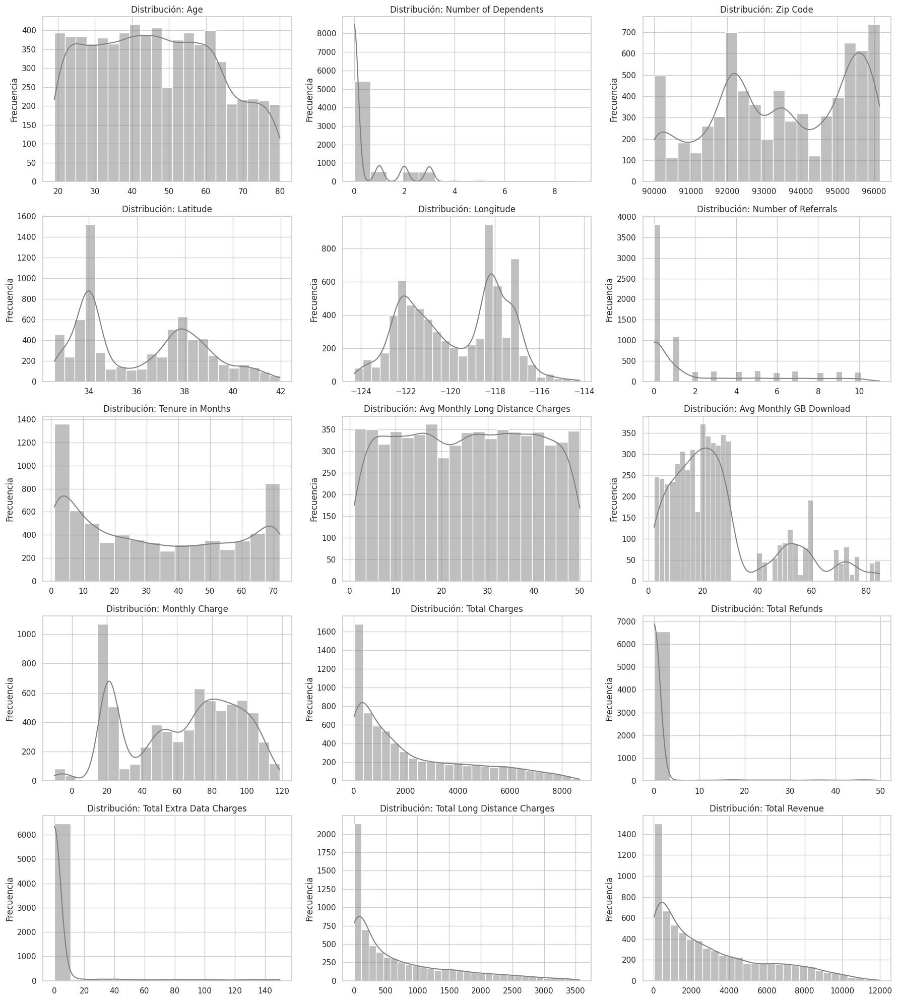

In [6]:
# Estilo general
sns.set(style="whitegrid")

# Seleccionar solo columnas numéricas del DataFrame df_encoded
numericas = df_original.select_dtypes(include=np.number)

# Número de variables numéricas
num_vars = numericas.shape[1]

# Definir tamaño del grid de subplots
cols = 3
rows = (num_vars + cols - 1) // cols

# Crear figura
fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4 * rows))
axes = axes.flatten()

# Generar gráficos de distribución para cada variable
for i, col in enumerate(numericas.columns):
    sns.histplot(data=numericas, x=col, kde=True, ax=axes[i], color='gray')
    axes[i].set_title(f'Distribución: {col}', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frecuencia')

# Eliminar ejes vacíos si hay más subplots que variables
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

####Booleanas

In [7]:
sns.set(style="whitegrid")

booleanas = df_original.select_dtypes(include=bool)

if booleanas.shape[1] == 0:
    print("No hay variables booleanas en el DataFrame.")
else:
    num_bools = booleanas.shape[1]
    cols = 3
    rows = (num_bools + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4 * rows))
    axes = axes.flatten()

    for i, col in enumerate(booleanas.columns):
        sns.countplot(data=booleanas, x=col, hue=col, palette="Set2", ax=axes[i], legend=False)
        axes[i].set_title(f'Frecuencia: {col}', fontsize=12)
        axes[i].set_xlabel('')
        axes[i].set_ylabel('Cantidad')

        for p in axes[i].patches:
            height = p.get_height()
            axes[i].text(p.get_x() + p.get_width() / 2., height + 0.5,
                         f'{int(height)}', ha="center", fontsize=9)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()



No hay variables booleanas en el DataFrame.




## Análisis univariado

Se analizaron los **momentos estadísticos** principales de las variables numéricas para entender su distribución y comportamiento:

- **Primer momento (Media):** Valor promedio de la variable.
- **Segundo momento (Varianza / Desviación estándar):** Medida de dispersión respecto a la media.
- **Tercer momento (Asimetría):** Mide la simetría de la distribución.
- **Cuarto momento (Curtosis):** Mide la concentración de los datos en los extremos (colas) de la distribución.



In [8]:
# Filtrar solo las columnas numéricas
numericas = df_original.select_dtypes(include=[np.number])

# Crear un nuevo DataFrame con los momentos estadísticos
momentos_estadisticos = pd.DataFrame({
    'Media': numericas.mean(),
    'Varianza': numericas.var(),
    'Desviación estándar': numericas.std(),
    'Asimetría': numericas.apply(skew),
    'Curtosis': numericas.apply(kurtosis)  # Curtosis centrada (exceso)
})

# Mostrar resultados
print(momentos_estadisticos)


                                          Media      Varianza  \
Age                                   46.509726  2.805743e+02   
Number of Dependents                   0.468692  9.269876e-01   
Zip Code                           93486.070567  3.447586e+06   
Latitude                              36.197455  6.095609e+00   
Longitude                           -119.756684  4.641547e+00   
Number of Referrals                    1.951867  9.007197e+00   
Tenure in Months                      32.386767  6.023128e+02   
Avg Monthly Long Distance Charges     25.420517  2.016506e+02   
Avg Monthly GB Download               26.189958  3.836343e+02   
Monthly Charge                        63.596131  9.737360e+02   
Total Charges                       2280.381264  5.135755e+06   
Total Refunds                          1.962182  6.245131e+01   
Total Extra Data Charges               6.860713  6.302599e+02   
Total Long Distance Charges          749.099262  7.168332e+05   
Total Revenue            

### Análisis de los Momentos Estadísticos

A continuación se presenta un análisis descriptivo de las variables numéricas del conjunto de datos, basado en los cuatro momentos estadísticos clásicos: media, varianza, asimetría y curtosis.

### 1. Primer momento: Media

La media indica el valor promedio de cada variable. Algunos valores destacados:

- **Edad (`Age`)**: promedio de aproximadamente **46.5 años**.
- **Tenure in Months**: los clientes han estado en promedio **32 meses** en la compañía.
- **Monthly Charge**: el cargo mensual promedio es de aproximadamente **$63.60**.

- **Total Revenue**: en promedio, cada cliente ha generado **$3,034.38** en ingresos totales.

### 2. Segundo momento: Varianza y Desviación Estándar

Estas medidas reflejan la dispersión de los datos. Las variables con mayor dispersión incluyen:

- **Total Revenue** y **Total Charges**: presentan una **gran varianza y desviación estándar**, indicando una alta variabilidad entre los clientes.
- **Zip Code**: también muestra una alta varianza, aunque esta variable no es continua en un sentido útil para modelos predictivos.

### 3. Tercer momento: Asimetría

La asimetría mide la simetría de la distribución de los datos. Algunos puntos clave:

- **Total Refunds** y **Total Extra Data Charges** presentan una **alta asimetría positiva**, lo que indica que la mayoría de los valores son bajos pero hay algunos valores extremadamente altos.
- **Number of Dependents** también tiene una asimetría positiva significativa (**2.10**), sugiriendo que muchos clientes no tienen dependientes, pero algunos tienen varios.
- Variables como **Monthly Charge** y **Longitude** tienen una asimetría cercana a cero, indicando una distribución aproximadamente simétrica.

### 4. Cuarto momento: Curtosis

La curtosis describe la concentración de valores en las colas de la distribución:

- **Total Refunds** (18.33) y **Total Extra Data Charges** (16.45) muestran una **curtosis muy alta**, lo que indica la presencia de valores extremos (colas pesadas).
- Varias variables como `Age`, `Latitude`, `Tenure in Months`, y `Zip Code` presentan **curtosis negativa**, lo que sugiere distribuciones más planas que la normal (colas ligeras).

### 5. Datos faltantes

- Las métricas de **Asimetría** y **Curtosis** no están disponibles (`NaN`) para algunas variables como `Avg Monthly Long Distance Charges` y `Avg Monthly GB Download`. Esto puede deberse a datos faltantes o a una distribución constante en los registros.

---

**Conclusión:**  
El análisis de los momentos estadísticos revela la presencia de **distribuciones sesgadas** y **valores atípicos** en varias variables, especialmente en las relacionadas con cargos extra y reembolsos. Esto puede ser importante para la transformación de datos previa al modelado, como aplicar logaritmos o normalizaciones.



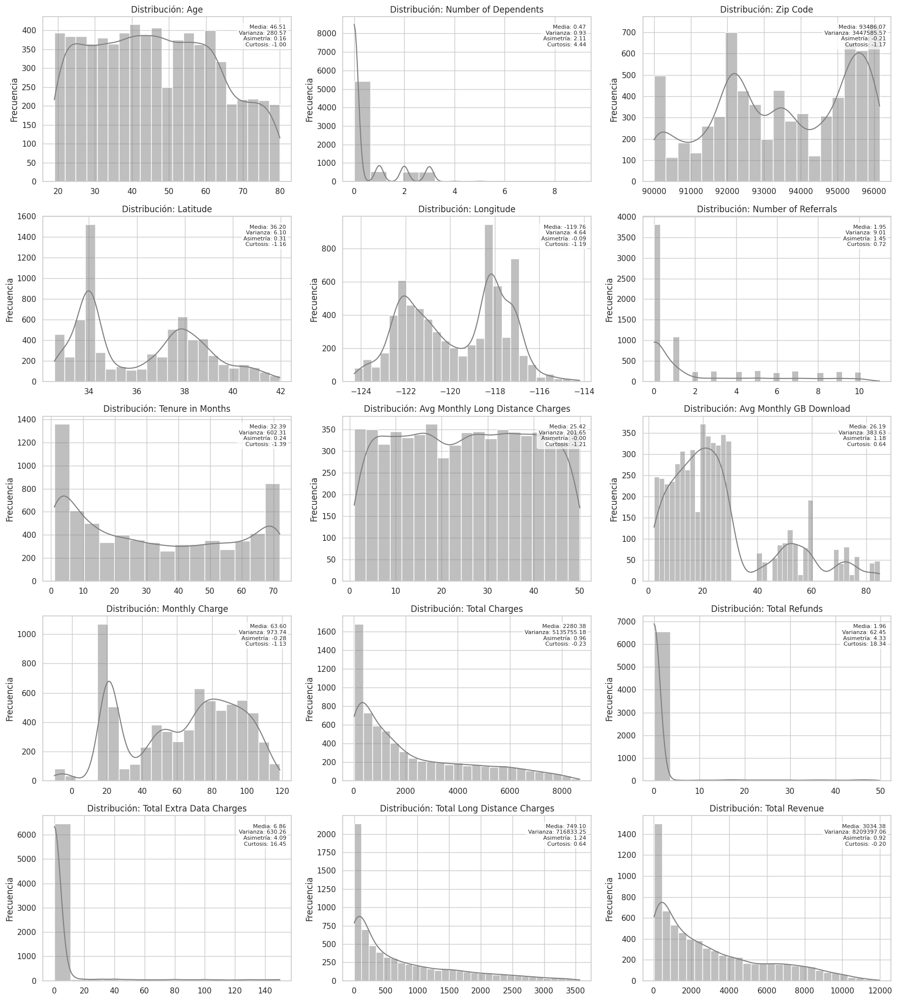

In [9]:
# Estilo general
sns.set(style="whitegrid")

# Seleccionar solo columnas numéricas
numericas = df_original.select_dtypes(include=np.number)

# Número de variables
num_vars = numericas.shape[1]

# Tamaño del grid de subplots
cols = 3
rows = (num_vars + cols - 1) // cols

# Crear figura
fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4 * rows))
axes = axes.flatten()

# Generar gráficos por cada variable
for i, col in enumerate(numericas.columns):
    data_col = numericas[col].dropna()

    # Calcular momentos estadísticos
    media = data_col.mean()
    varianza = data_col.var()
    asimetria = skew(data_col)
    curtosis = kurtosis(data_col)

    # Plot
    sns.histplot(data=data_col, kde=True, ax=axes[i], color='gray')
    axes[i].set_title(f'Distribución: {col}', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frecuencia')

    # Agregar texto con los momentos estadísticos
    texto = (f"Media: {media:.2f}\n"
             f"Varianza: {varianza:.2f}\n"
             f"Asimetría: {asimetria:.2f}\n"
             f"Curtosis: {curtosis:.2f}")

    axes[i].text(0.98, 0.95, texto, transform=axes[i].transAxes,
                 fontsize=8, va='top', ha='right',
                 bbox=dict(boxstyle="round,pad=0.3", facecolor='white', alpha=0.7))

# Eliminar ejes vacíos si hay
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


##Boxplots

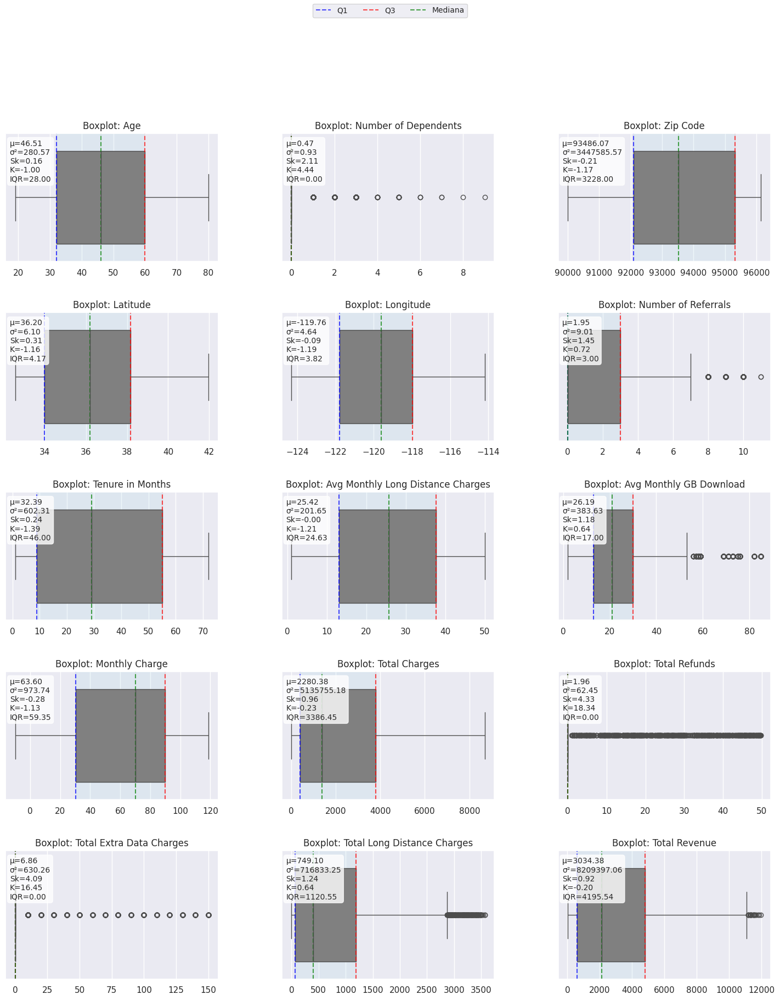

In [10]:
# Estilo gráfico
sns.set(style="darkgrid")

# Filtrar columnas numéricas
numericas = df_original.select_dtypes(include='number')

# Crear figura y subplots
num_vars = numericas.shape[1]
fig, axes = plt.subplots(nrows=(num_vars + 2) // 3, ncols=3, figsize=(18, 4 * ((num_vars + 2) // 3)))
axes = axes.flatten()

# Dibujar boxplots con anotaciones
for i, col in enumerate(numericas.columns):
    data = numericas[col].dropna()
    sns.boxplot(x=data, ax=axes[i], color='gray')

    # Título
    axes[i].set_title(f'Boxplot: {col}', fontsize=12)
    axes[i].set_xlabel('')

    # Calcular estadísticos
    media = data.mean()
    varianza = data.var()
    asimetria = skew(data)
    curtosis_val = kurtosis(data)

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    mediana = data.median()
    iqr = q3 - q1

    # Cuadro de texto con momentos
    texto = f"μ={media:.2f}\nσ²={varianza:.2f}\nSk={asimetria:.2f}\nK={curtosis_val:.2f}\nIQR={iqr:.2f}"
    axes[i].text(0.02, 0.95, texto, transform=axes[i].transAxes,
                 fontsize=10, verticalalignment='top',
                 bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    # Marcar Q1, Q3, mediana y IQR
    axes[i].axvline(q1, color='blue', linestyle='--', label='Q1' if i == 0 else "", alpha=0.7)
    axes[i].axvline(q3, color='red', linestyle='--', label='Q3' if i == 0 else "", alpha=0.7)
    axes[i].axvline(mediana, color='green', linestyle='--', label='Mediana' if i == 0 else "", alpha=0.7)
    axes[i].fill_betweenx([0, 1], q1, q3, color='lightblue', alpha=0.2, transform=axes[i].get_xaxis_transform())

# Eliminar subplots vacíos
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Agregar leyenda solo una vez
handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc='upper center', ncol=3, fontsize=10)

# Ajustar diseño
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.show()


## Covarianza y Correlacion

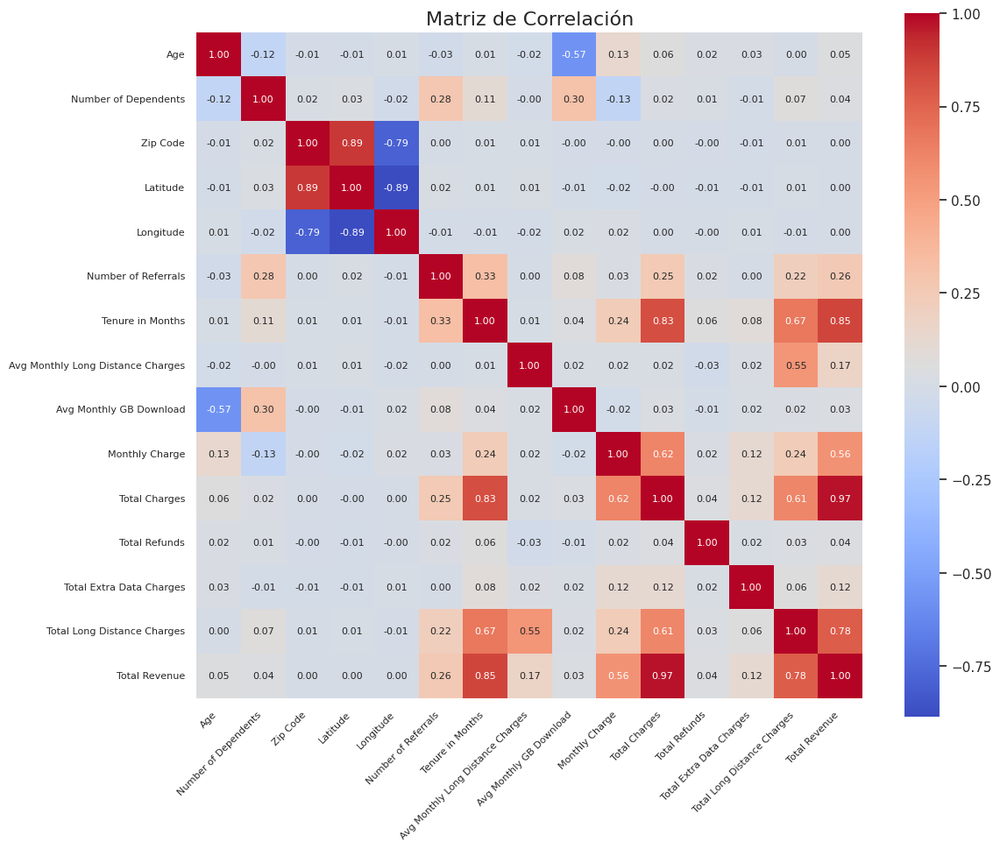

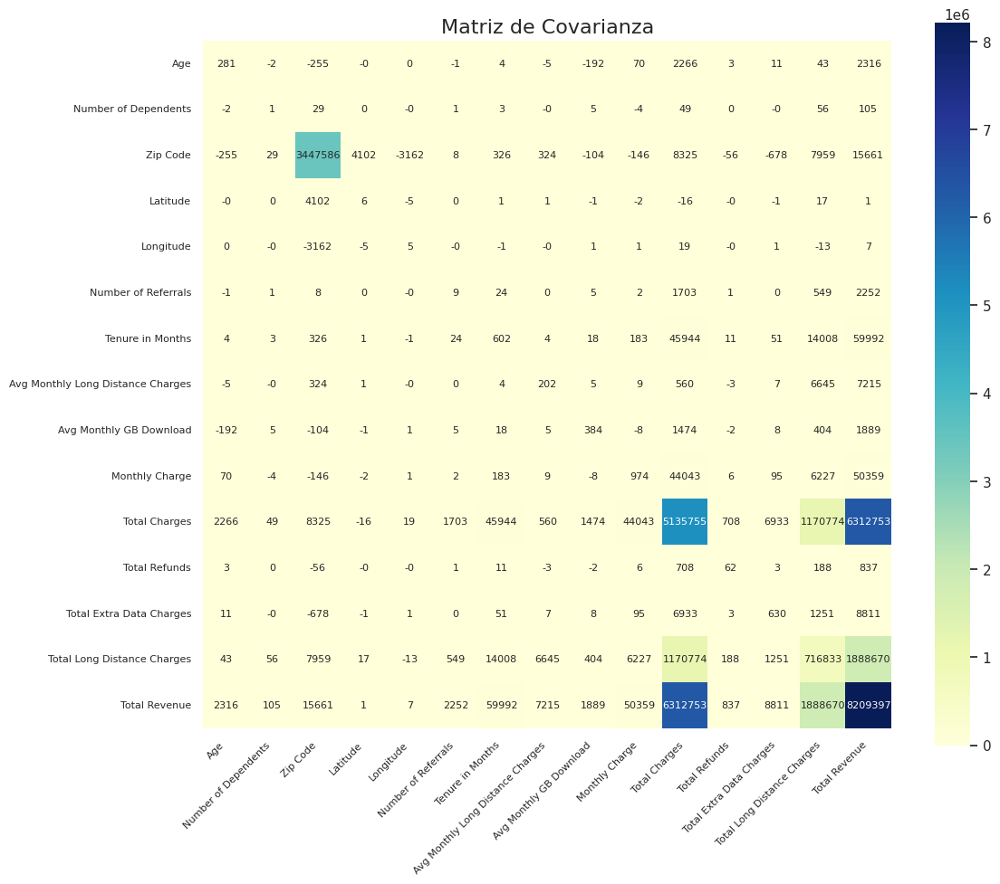

In [11]:

# Selección de variables numéricas
numericas = df_original.select_dtypes(include=np.number)

# === Matriz de Correlación ===
corr_matrix = numericas.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix,
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            square=True,
            annot_kws={"size": 8})  # Tamaño de fuente reducido
plt.title("Matriz de Correlación", fontsize=16)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

# === Matriz de Covarianza ===
cov_matrix = numericas.cov()

plt.figure(figsize=(12, 10))
sns.heatmap(cov_matrix,
            annot=True,
            fmt=".0f",
            cmap="YlGnBu",
            square=True,
            annot_kws={"size": 8})  # Tamaño de fuente reducido
plt.title("Matriz de Covarianza", fontsize=16)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()


# Limpieza y Preprocesamiento de datos


A continuación realizaremos un análisis de los datos:

---



In [12]:
cuali = df.select_dtypes('object').columns.to_list() #Hacer una columna de lista de todos donde su tipo es objeto
cuanti = df.select_dtypes('number').columns.to_list() #Hacer una columna de lista de todos donde su tipo es numerico

len(cuali), cuali
len(cuanti), cuanti

(15,
 ['Age',
  'Number of Dependents',
  'Zip Code',
  'Latitude',
  'Longitude',
  'Number of Referrals',
  'Tenure in Months',
  'Avg Monthly Long Distance Charges',
  'Avg Monthly GB Download',
  'Monthly Charge',
  'Total Charges',
  'Total Refunds',
  'Total Extra Data Charges',
  'Total Long Distance Charges',
  'Total Revenue'])

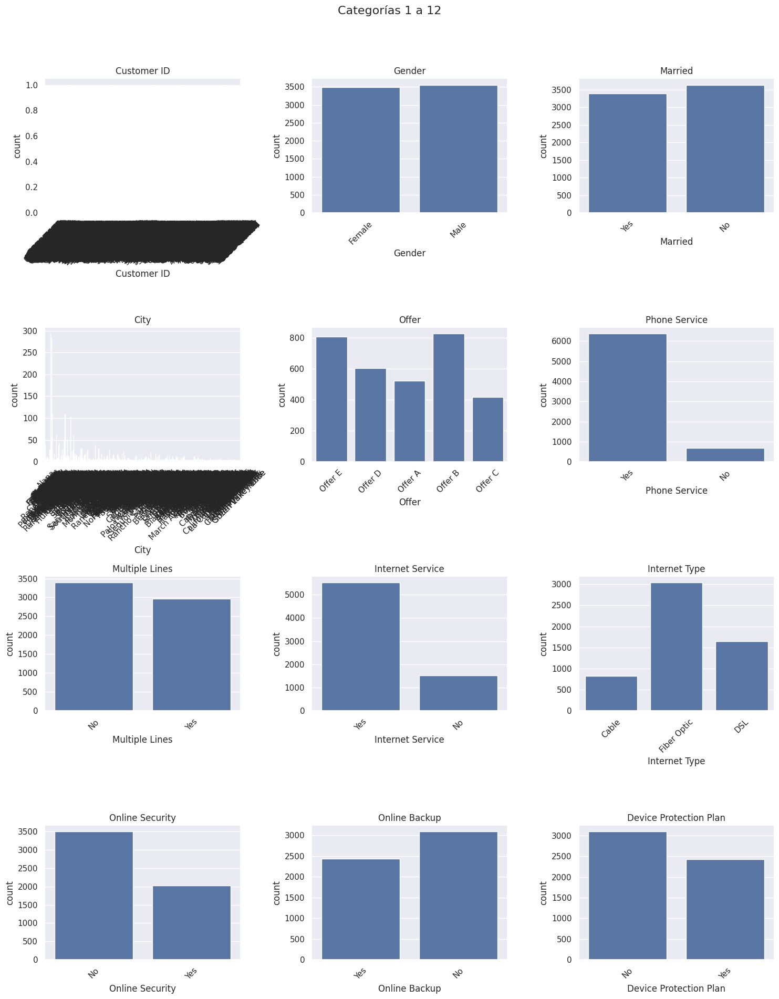

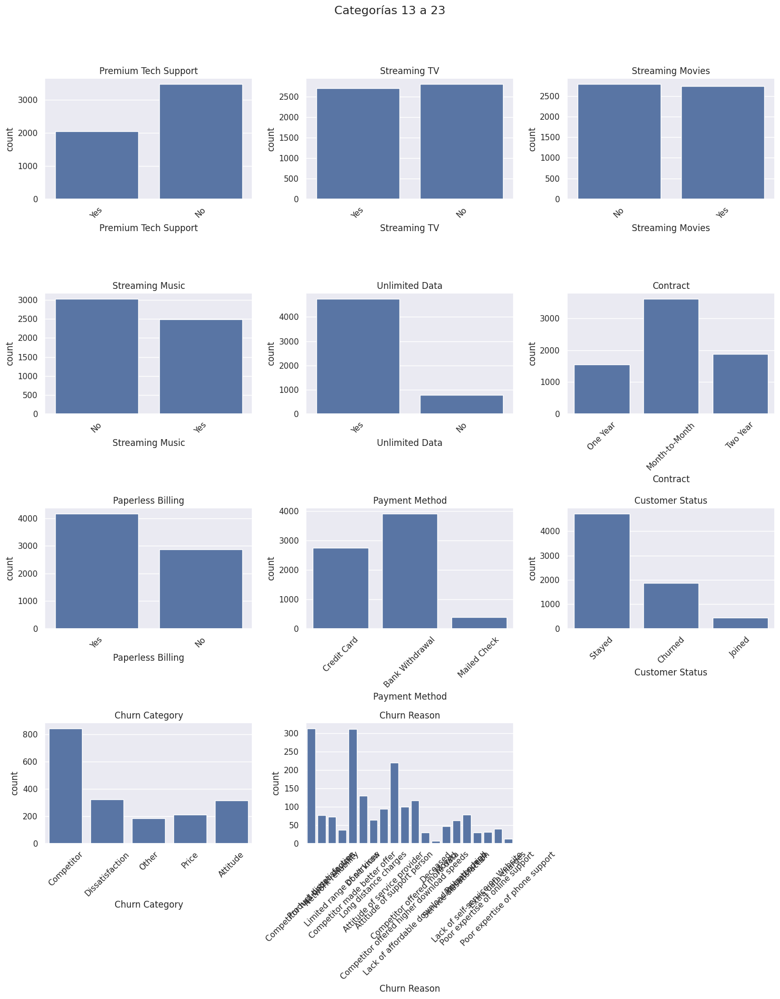

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

cols_per_fig = 12

for i in range(0, len(cuali), cols_per_fig):
    subset = cuali[i:i+cols_per_fig]
    n = len(subset)
    cols = 3
    rows = (n + cols - 1) // cols  # redondeo hacia arriba

    fig = plt.figure(figsize=(5 * cols, 5 * rows))
    fig.suptitle(f'Categorías {i+1} a {i+n}', fontsize=16)

    for idx, col_name in enumerate(subset):
        plt.subplot(rows, cols, idx + 1)
        sns.countplot(x=df[col_name])
        plt.title(col_name)
        plt.xticks(rotation=45)  # por si hay etiquetas largas

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # dejar espacio para el título
    plt.show()

In [14]:
cuali.remove('Customer ID')
cuali.remove('City')
cuali.remove('Churn Reason')
cuali.remove('Churn Category')
cuanti.remove('Zip Code')
cuanti.remove('Latitude')
cuanti.remove('Longitude')

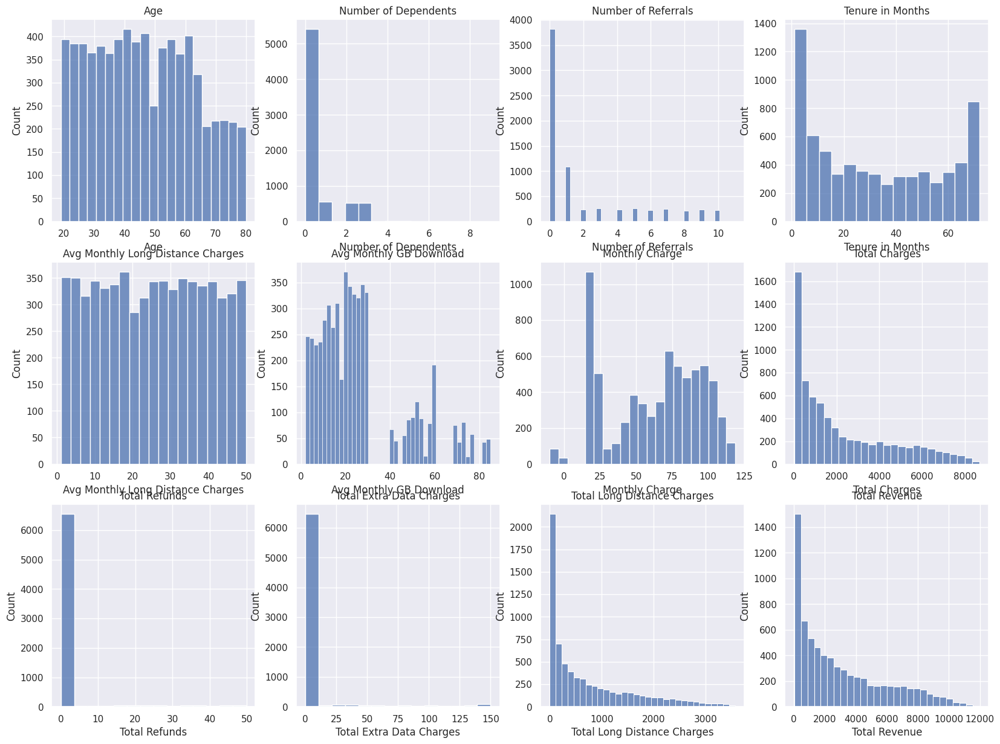

In [15]:
#Para hacer los histogramas pero ahora de las variables cuantificables
# Histograma para variables cuantitativas
fig = plt.figure(figsize=(20,20))
for idx, col_name in enumerate(cuanti):
    plt.subplot(4, 4, idx+1)
    sns.histplot(df[col_name])  # kde=True para una curva de densidad
    plt.title(col_name)
plt.show()

In [16]:
df_cuali = df.select_dtypes('object')
df_cuali.head()

,Customer ID,Gender,Married,City,Offer,Phone Service,Multiple Lines,Internet Service,Internet Type,Online Security,...,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,Yes,Frazier Park,NaN,Yes,No,Yes,Cable,No,...,Yes,No,No,Yes,One Year,Yes,Credit Card,Stayed,NaN,NaN
1,0003-MKNFE,Male,No,Glendale,NaN,Yes,Yes,Yes,Cable,No,...,No,Yes,Yes,No,Month-to-Month,No,Credit Card,Stayed,NaN,NaN
2,0004-TLHLJ,Male,No,Costa Mesa,Offer E,Yes,No,Yes,Fiber Optic,No,...,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,Yes,Martinez,Offer D,Yes,No,Yes,Fiber Optic,No,...,Yes,Yes,No,Yes,Month-to-Month,Yes,Bank Withdrawal,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,Yes,Camarillo,NaN,Yes,No,Yes,Fiber Optic,No,...,Yes,No,No,Yes,Month-to-Month,Yes,Credit Card,Churned,Dissatisfaction,Network reliability


In [17]:
# Asegurándonos de que estamos trabajando con una variable cualitativa
# En este caso, 'fueltype' es una variable cualitativa en el dataset.

# Mostrar las primeras filas de la columna 'fueltype' antes del One-Hot Encoding
print("Subtabla antes de One-Hot Encoding:")
print(df[['Gender']].head())

# Aplicar One-Hot Encoding a la columna 'fueltype'
df_encoded_fueltype = pd.get_dummies(df['Gender'], drop_first=False)

# Mostrar las primeras filas de la subtabla después del One-Hot Encoding
print("\nSubtabla después de One-Hot Encoding:")
print(df_encoded_fueltype.head())

Subtabla antes de One-Hot Encoding:
   Gender
0  Female
1    Male
2    Male
3    Male
4  Female

Subtabla después de One-Hot Encoding:
   Female   Male
0    True  False
1   False   True
2   False   True
3   False   True
4    True  False


In [18]:
# Aplicar One-Hot Encoding a todas las columnas de tipo 'object'
df[ df.select_dtypes(include='bool').columns ] = df.select_dtypes(include='bool').astype(int)
df_encoded = pd.get_dummies(df, columns=cuali, drop_first=False)



# Mostrar las primeras 5 instancias del DataFrame después de aplicar One-Hot Encoding
print("\nDataFrame después de One-Hot Encoding:")
print(df_encoded.head())  # Mostramos las primeras 5 filas del DataFrame transformado


DataFrame después de One-Hot Encoding:
  Customer ID  Age  Number of Dependents          City  Zip Code   Latitude  \
0  0002-ORFBO   37                     0  Frazier Park     93225  34.827662   
1  0003-MKNFE   46                     0      Glendale     91206  34.162515   
2  0004-TLHLJ   50                     0    Costa Mesa     92627  33.645672   
3  0011-IGKFF   78                     0      Martinez     94553  38.014457   
4  0013-EXCHZ   75                     0     Camarillo     93010  34.227846   

    Longitude  Number of Referrals  Tenure in Months  \
0 -118.999073                    2                 9   
1 -118.203869                    0                 9   
2 -117.922613                    0                 4   
3 -122.115432                    1                13   
4 -119.079903                    3                 3   

   Avg Monthly Long Distance Charges  ...  Contract_One Year  \
0                              42.39  ...               True   
1                   

In [19]:
cols_to_drop = ['Customer ID', 'Zip Code', 'Churn Category', 'Churn Reason', 'City', 'Longitude', 'Latitude']
df_encoded = df_encoded.drop(columns=cols_to_drop)

df_encoded.isnull().sum().sort_values(ascending=False)
#len(df_encoded.columns)
#print(df_encoded.columns)

,0
Avg Monthly GB Download,1526
Avg Monthly Long Distance Charges,682
Age,0
Number of Referrals,0
Number of Dependents,0
Tenure in Months,0
Monthly Charge,0
Total Charges,0
Total Refunds,0
Total Extra Data Charges,0


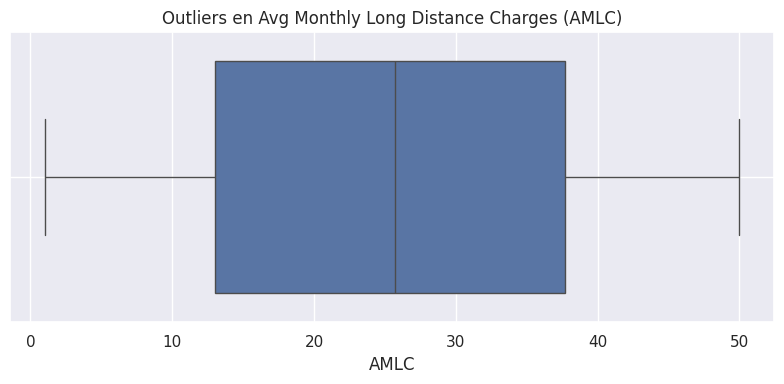

In [20]:
amlc = df["Avg Monthly Long Distance Charges"]


# Boxplot para detectar outliers
plt.figure(figsize=(8, 4))
sns.boxplot(x=amlc)
plt.title("Outliers en Avg Monthly Long Distance Charges (AMLC)")
plt.xlabel("AMLC")
plt.grid(True)
plt.tight_layout()
plt.show()

In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer


# Selección de columnas relevantes para imputación
cols_to_impute = ['Avg Monthly GB Download', 'Avg Monthly Long Distance Charges']

# Crear copia del DataFrame solo con las columnas necesarias
impute_df = df_encoded[cols_to_impute].copy()

# Escalar los datos antes de aplicar KNNImputer
scaler = StandardScaler()
scaled_data = scaler.fit_transform(impute_df)

# Aplicar KNNImputer (por defecto n_neighbors=5)
knn_imputer = KNNImputer()
imputed_data = knn_imputer.fit_transform(scaled_data)

# Invertir el escalado para regresar a valores originales
imputed_data_original = scaler.inverse_transform(imputed_data)

# Reemplazar los valores imputados en el DataFrame original
df_encoded[cols_to_impute] = imputed_data_original


# Verificar si ya no hay valores faltantes
missing_values_post_impute = df_encoded[cols_to_impute].isnull().sum()
missing_values_post_impute

,0
Avg Monthly GB Download,0
Avg Monthly Long Distance Charges,0


In [22]:
df_scaled = df_encoded.copy()
df_scaled[cuanti] = StandardScaler().fit_transform(df_scaled[cuanti])

df_scaled.head()
#df_encoded.head()

,Age,Number of Dependents,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,...,Contract_One Year,Contract_Two Year,Paperless Billing_No,Paperless Billing_Yes,Payment Method_Bank Withdrawal,Payment Method_Credit Card,Payment Method_Mailed Check,Customer Status_Churned,Customer Status_Joined,Customer Status_Stayed
0,-0.567773,-0.486835,0.016039,-0.952994,1.231654,-0.567728,0.064221,-0.744500,-0.248313,-0.273300,...,True,False,False,True,False,True,False,False,False,True
1,-0.030433,-0.486835,-0.650409,-0.952994,-1.095523,-0.905036,-2.166367,-0.766962,4.602325,0.125055,...,False,False,True,False,False,True,False,False,False,True
2,0.208385,-0.486835,-0.650409,-1.156740,0.590029,0.219325,0.330225,-0.882382,-0.248313,-0.273300,...,False,False,False,True,True,False,False,True,False,False
3,1.880110,-0.486835,-0.317185,-0.789997,0.162034,-1.242345,1.102599,-0.460063,-0.248313,-0.273300,...,False,False,False,True,True,False,False,True,False,False
4,1.700997,-0.486835,0.349263,-1.197489,-1.338519,-0.848818,0.650712,-0.888318,-0.248313,-0.273300,...,False,False,False,True,False,True,False,True,False,False


In [23]:
#Codificar la variable objetivo (Customer Status)

print(df_scaled.columns)

Index(['Age', 'Number of Dependents', 'Number of Referrals',
       'Tenure in Months', 'Avg Monthly Long Distance Charges',
       'Avg Monthly GB Download', 'Monthly Charge', 'Total Charges',
       'Total Refunds', 'Total Extra Data Charges',
       'Total Long Distance Charges', 'Total Revenue', 'Gender_Female',
       'Gender_Male', 'Married_No', 'Married_Yes', 'Offer_Offer A',
       'Offer_Offer B', 'Offer_Offer C', 'Offer_Offer D', 'Offer_Offer E',
       'Phone Service_No', 'Phone Service_Yes', 'Multiple Lines_No',
       'Multiple Lines_Yes', 'Internet Service_No', 'Internet Service_Yes',
       'Internet Type_Cable', 'Internet Type_DSL', 'Internet Type_Fiber Optic',
       'Online Security_No', 'Online Security_Yes', 'Online Backup_No',
       'Online Backup_Yes', 'Device Protection Plan_No',
       'Device Protection Plan_Yes', 'Premium Tech Support_No',
       'Premium Tech Support_Yes', 'Streaming TV_No', 'Streaming TV_Yes',
       'Streaming Movies_No', 'Streaming Movies

In [24]:
df_scaled['churn'] = df_scaled['Customer Status_Churned']
df_scaled.drop(['Customer Status_Churned', 'Customer Status_Joined', 'Customer Status_Stayed'], axis=1, inplace=True)
df_scaled['churn'] = df_scaled['churn'].astype(int)

print(df_scaled['churn'])

0       0
1       0
2       1
3       1
4       1
       ..
7038    0
7039    1
7040    0
7041    0
7042    0
Name: churn, Length: 7043, dtype: int64


In [25]:
print(df_scaled['churn'].value_counts())
print(df_scaled['churn'].value_counts(normalize=True) * 100)

churn
0    5174
1    1869
Name: count, dtype: int64
churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64


In [26]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 57 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Age                                7043 non-null   int64  
 1   Number of Dependents               7043 non-null   int64  
 2   Number of Referrals                7043 non-null   int64  
 3   Tenure in Months                   7043 non-null   int64  
 4   Avg Monthly Long Distance Charges  7043 non-null   float64
 5   Avg Monthly GB Download            7043 non-null   float64
 6   Monthly Charge                     7043 non-null   float64
 7   Total Charges                      7043 non-null   float64
 8   Total Refunds                      7043 non-null   float64
 9   Total Extra Data Charges           7043 non-null   int64  
 10  Total Long Distance Charges        7043 non-null   float64
 11  Total Revenue                      7043 non-null   float

In [27]:
df_scaled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 55 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Age                                7043 non-null   float64
 1   Number of Dependents               7043 non-null   float64
 2   Number of Referrals                7043 non-null   float64
 3   Tenure in Months                   7043 non-null   float64
 4   Avg Monthly Long Distance Charges  7043 non-null   float64
 5   Avg Monthly GB Download            7043 non-null   float64
 6   Monthly Charge                     7043 non-null   float64
 7   Total Charges                      7043 non-null   float64
 8   Total Refunds                      7043 non-null   float64
 9   Total Extra Data Charges           7043 non-null   float64
 10  Total Long Distance Charges        7043 non-null   float64
 11  Total Revenue                      7043 non-null   float

# Estadística Descriptiva (Datos procesados)

##Librerias a usar

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis

##Tipos de datos

In [29]:
# Ver cantidad total de columnas
total_variables = df_encoded.shape[1]

# Contar tipos de datos
tipos = df_encoded.dtypes.value_counts()

# Mostrar resumen
print(f"Total de variables: {total_variables}\n")
print("Cantidad de variables por tipo:")
print(tipos)

# Resumen más detallado: numéricas, categóricas, booleanas, fechas
tipos_detallados = {
    'Numéricas': df_encoded.select_dtypes(include=['number']).shape[1],
    'Categóricas': df_encoded.select_dtypes(include=['object', 'category']).shape[1],
    'Booleanas': df_encoded.select_dtypes(include=['bool']).shape[1],
    'Fechas': df_encoded.select_dtypes(include=['datetime64']).shape[1]
}

print("\nResumen por categoría de variable:")
for tipo, cantidad in tipos_detallados.items():
    print(f"{tipo}: {cantidad}")

Total de variables: 57

Cantidad de variables por tipo:
bool       45
float64     7
int64       5
Name: count, dtype: int64

Resumen por categoría de variable:
Numéricas: 12
Categóricas: 0
Booleanas: 45
Fechas: 0


##Sin escalar


### Distribuciones


####Numéricas

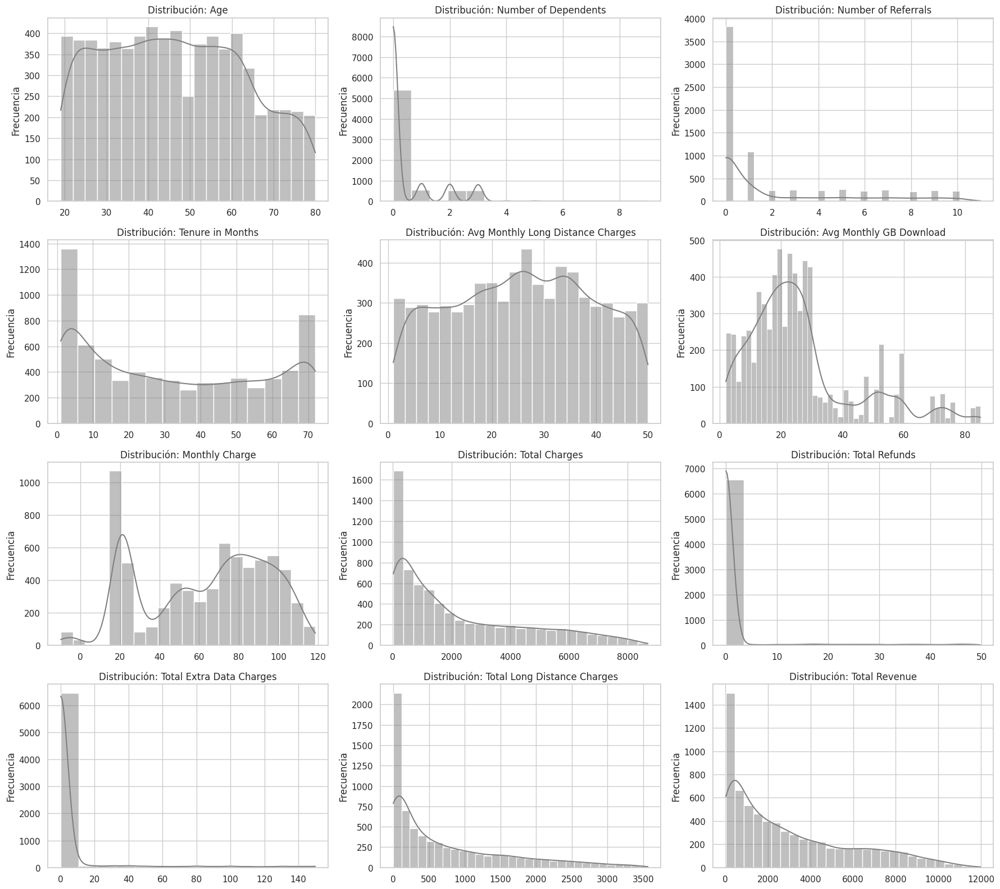

In [30]:
# Estilo general
sns.set(style="whitegrid")

# Seleccionar solo columnas numéricas del DataFrame df_encoded
numericas = df_encoded.select_dtypes(include=np.number)

# Número de variables numéricas
num_vars = numericas.shape[1]

# Definir tamaño del grid de subplots
cols = 3
rows = (num_vars + cols - 1) // cols

# Crear figura
fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4 * rows))
axes = axes.flatten()

# Generar gráficos de distribución para cada variable
for i, col in enumerate(numericas.columns):
    sns.histplot(data=numericas, x=col, kde=True, ax=axes[i], color='gray')
    axes[i].set_title(f'Distribución: {col}', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frecuencia')

# Eliminar ejes vacíos si hay más subplots que variables
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

####Booleanas

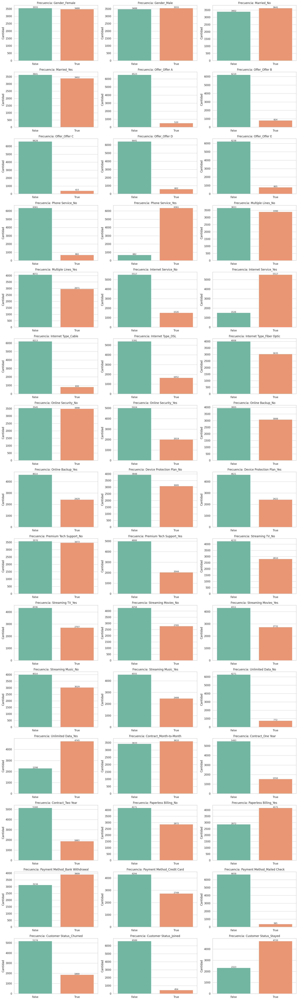

In [31]:
sns.set(style="whitegrid")

booleanas = df_encoded.select_dtypes(include=bool)

if booleanas.shape[1] == 0:
    print("No hay variables booleanas en el DataFrame.")
else:
    num_bools = booleanas.shape[1]
    cols = 3
    rows = (num_bools + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4 * rows))
    axes = axes.flatten()

    for i, col in enumerate(booleanas.columns):
        sns.countplot(data=booleanas, x=col, hue=col, palette="Set2", ax=axes[i], legend=False)
        axes[i].set_title(f'Frecuencia: {col}', fontsize=12)
        axes[i].set_xlabel('')
        axes[i].set_ylabel('Cantidad')

        for p in axes[i].patches:
            height = p.get_height()
            axes[i].text(p.get_x() + p.get_width() / 2., height + 0.5,
                         f'{int(height)}', ha="center", fontsize=9)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()





### Análisis univariado

Se analizaron los **momentos estadísticos** principales de las variables numéricas para entender su distribución y comportamiento:

- **Primer momento (Media):** Valor promedio de la variable.
- **Segundo momento (Varianza / Desviación estándar):** Medida de dispersión respecto a la media.
- **Tercer momento (Asimetría):** Mide la simetría de la distribución.
- **Cuarto momento (Curtosis):** Mide la concentración de los datos en los extremos (colas) de la distribución.



In [32]:
# Filtrar solo las columnas numéricas
numericas = df_encoded.select_dtypes(include=[np.number])

# Crear un nuevo DataFrame con los momentos estadísticos
momentos_estadisticos = pd.DataFrame({
    'Media': numericas.mean(),
    'Varianza': numericas.var(),
    'Desviación estándar': numericas.std(),
    'Asimetría': numericas.apply(skew),
    'Curtosis': numericas.apply(kurtosis)  # Curtosis centrada (exceso)
})

# Mostrar resultados
print(momentos_estadisticos)


                                         Media      Varianza  \
Age                                  46.509726  2.805743e+02   
Number of Dependents                  0.468692  9.269876e-01   
Number of Referrals                   1.951867  9.007197e+00   
Tenure in Months                     32.386767  6.023128e+02   
Avg Monthly Long Distance Charges    25.612835  1.855757e+02   
Avg Monthly GB Download              26.098680  3.164536e+02   
Monthly Charge                       63.596131  9.737360e+02   
Total Charges                      2280.381264  5.135755e+06   
Total Refunds                         1.962182  6.245131e+01   
Total Extra Data Charges              6.860713  6.302599e+02   
Total Long Distance Charges         749.099262  7.168332e+05   
Total Revenue                      3034.379056  8.209397e+06   

                                   Desviación estándar  Asimetría   Curtosis  
Age                                          16.750352   0.162152  -1.002989  
Number of

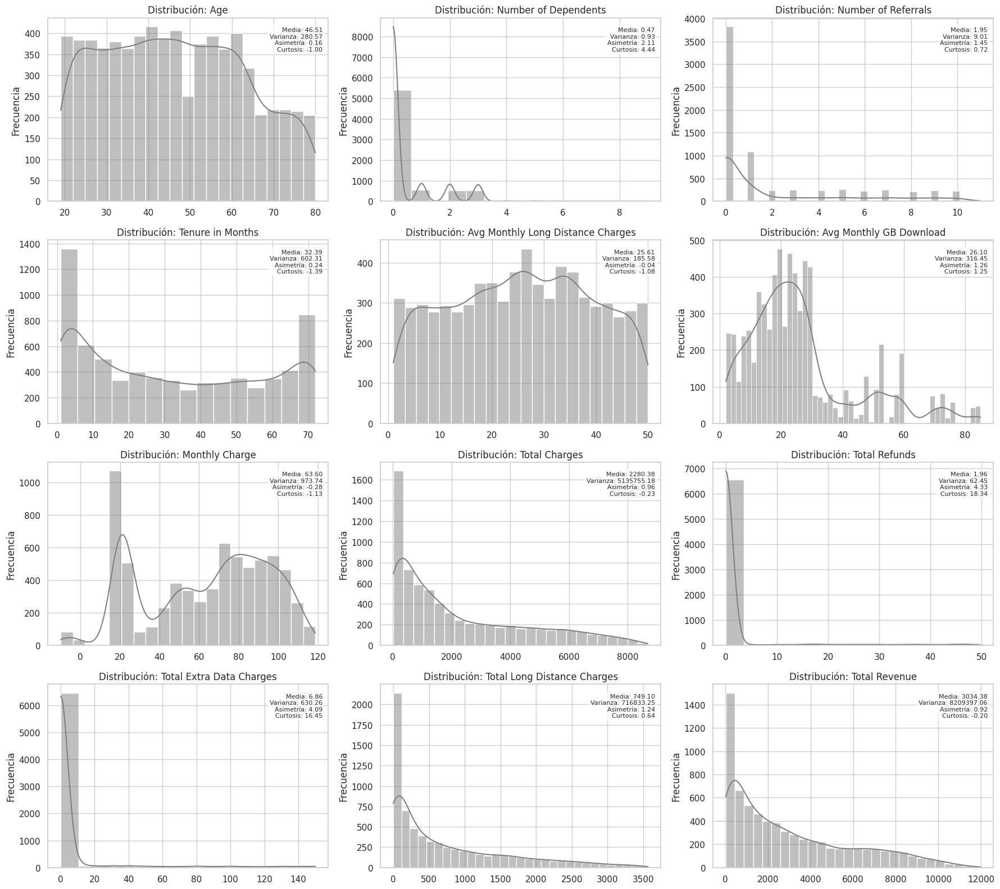

In [33]:
6# Estilo general
sns.set(style="whitegrid")

# Seleccionar solo columnas numéricas
numericas = df_encoded.select_dtypes(include=np.number)

# Número de variables
num_vars = numericas.shape[1]

# Tamaño del grid de subplots
cols = 3
rows = (num_vars + cols - 1) // cols

# Crear figura
fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4 * rows))
axes = axes.flatten()

# Generar gráficos por cada variable
for i, col in enumerate(numericas.columns):
    data_col = numericas[col].dropna()

    # Calcular momentos estadísticos
    media = data_col.mean()
    varianza = data_col.var()
    asimetria = skew(data_col)
    curtosis = kurtosis(data_col)

    # Plot
    sns.histplot(data=data_col, kde=True, ax=axes[i], color='gray')
    axes[i].set_title(f'Distribución: {col}', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frecuencia')

    # Agregar texto con los momentos estadísticos
    texto = (f"Media: {media:.2f}\n"
             f"Varianza: {varianza:.2f}\n"
             f"Asimetría: {asimetria:.2f}\n"
             f"Curtosis: {curtosis:.2f}")

    axes[i].text(0.98, 0.95, texto, transform=axes[i].transAxes,
                 fontsize=8, va='top', ha='right',
                 bbox=dict(boxstyle="round,pad=0.3", facecolor='white', alpha=0.7))

# Eliminar ejes vacíos si hay
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


###Boxplots

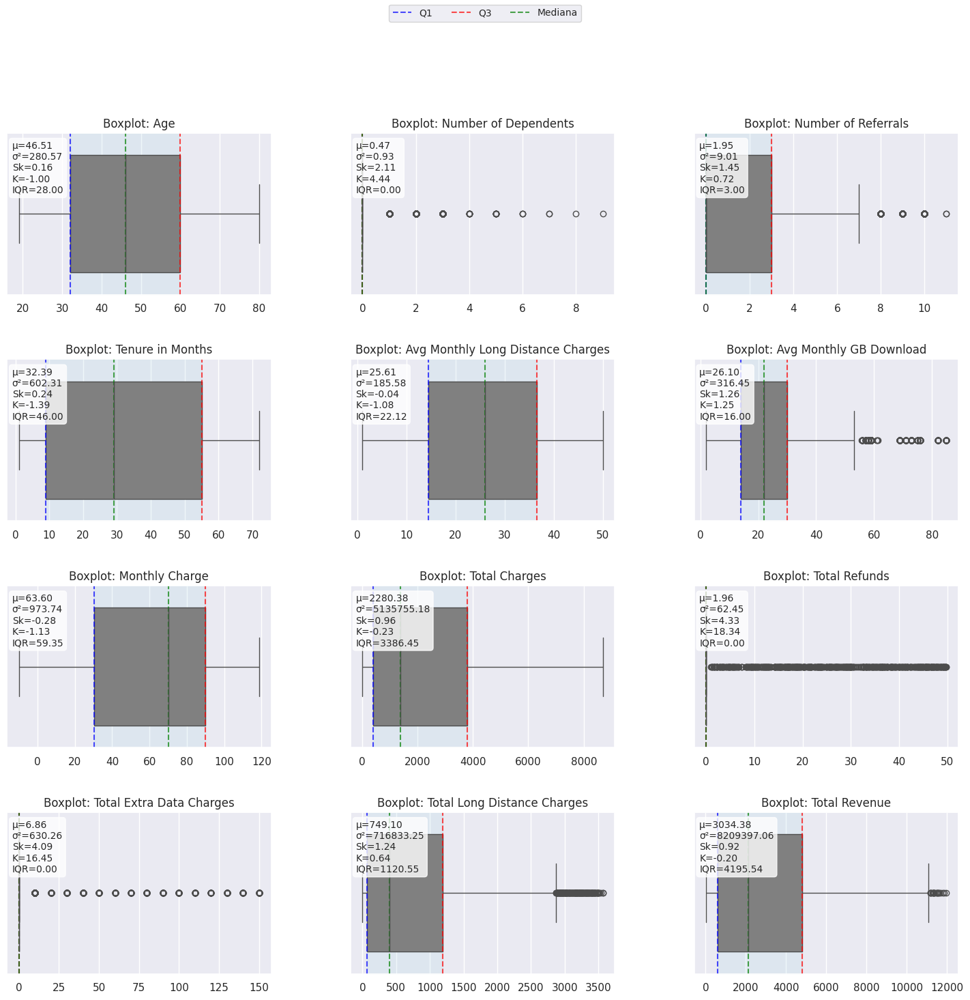

In [34]:
# Estilo gráfico
sns.set(style="darkgrid")

# Filtrar columnas numéricas
numericas = df_encoded.select_dtypes(include='number')

# Crear figura y subplots
num_vars = numericas.shape[1]
fig, axes = plt.subplots(nrows=(num_vars + 2) // 3, ncols=3, figsize=(18, 4 * ((num_vars + 2) // 3)))
axes = axes.flatten()

# Dibujar boxplots con anotaciones
for i, col in enumerate(numericas.columns):
    data = numericas[col].dropna()
    sns.boxplot(x=data, ax=axes[i], color='gray')

    # Título
    axes[i].set_title(f'Boxplot: {col}', fontsize=12)
    axes[i].set_xlabel('')

    # Calcular estadísticos
    media = data.mean()
    varianza = data.var()
    asimetria = skew(data)
    curtosis_val = kurtosis(data)

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    mediana = data.median()
    iqr = q3 - q1

    # Cuadro de texto con momentos
    texto = f"μ={media:.2f}\nσ²={varianza:.2f}\nSk={asimetria:.2f}\nK={curtosis_val:.2f}\nIQR={iqr:.2f}"
    axes[i].text(0.02, 0.95, texto, transform=axes[i].transAxes,
                 fontsize=10, verticalalignment='top',
                 bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    # Marcar Q1, Q3, mediana y IQR
    axes[i].axvline(q1, color='blue', linestyle='--', label='Q1' if i == 0 else "", alpha=0.7)
    axes[i].axvline(q3, color='red', linestyle='--', label='Q3' if i == 0 else "", alpha=0.7)
    axes[i].axvline(mediana, color='green', linestyle='--', label='Mediana' if i == 0 else "", alpha=0.7)
    axes[i].fill_betweenx([0, 1], q1, q3, color='lightblue', alpha=0.2, transform=axes[i].get_xaxis_transform())

# Eliminar subplots vacíos
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Agregar leyenda solo una vez
handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc='upper center', ncol=3, fontsize=10)

# Ajustar diseño
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.show()


### Covarianza y Correlacion

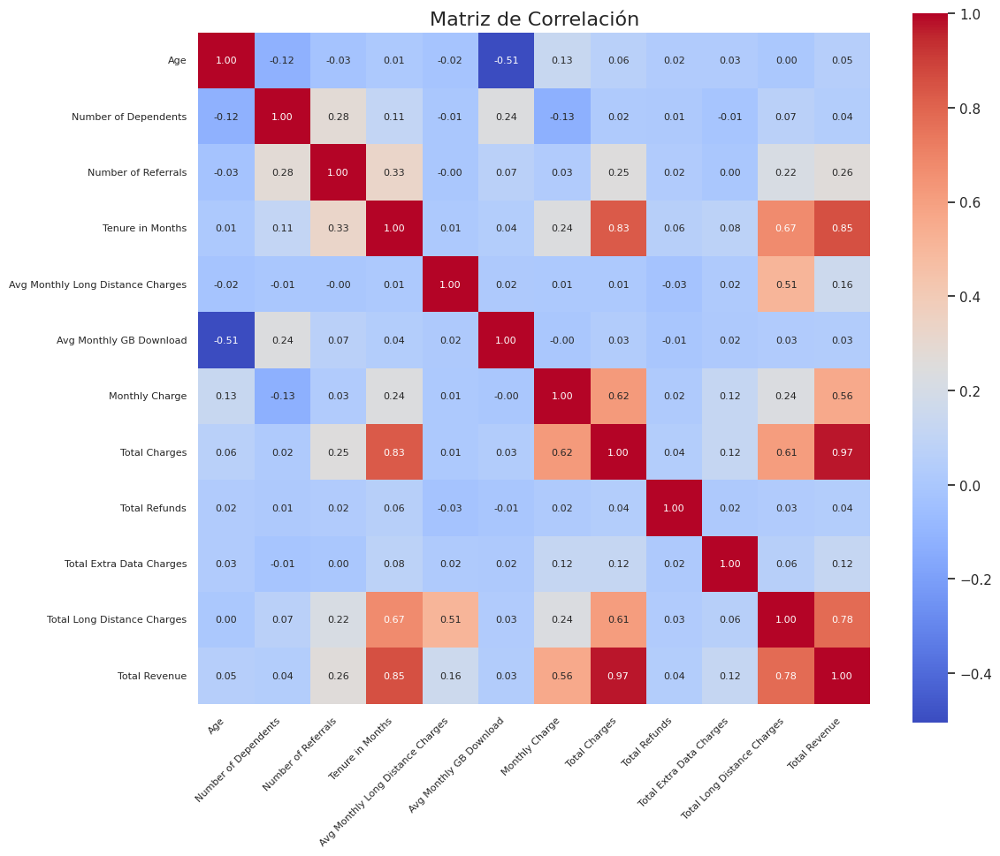

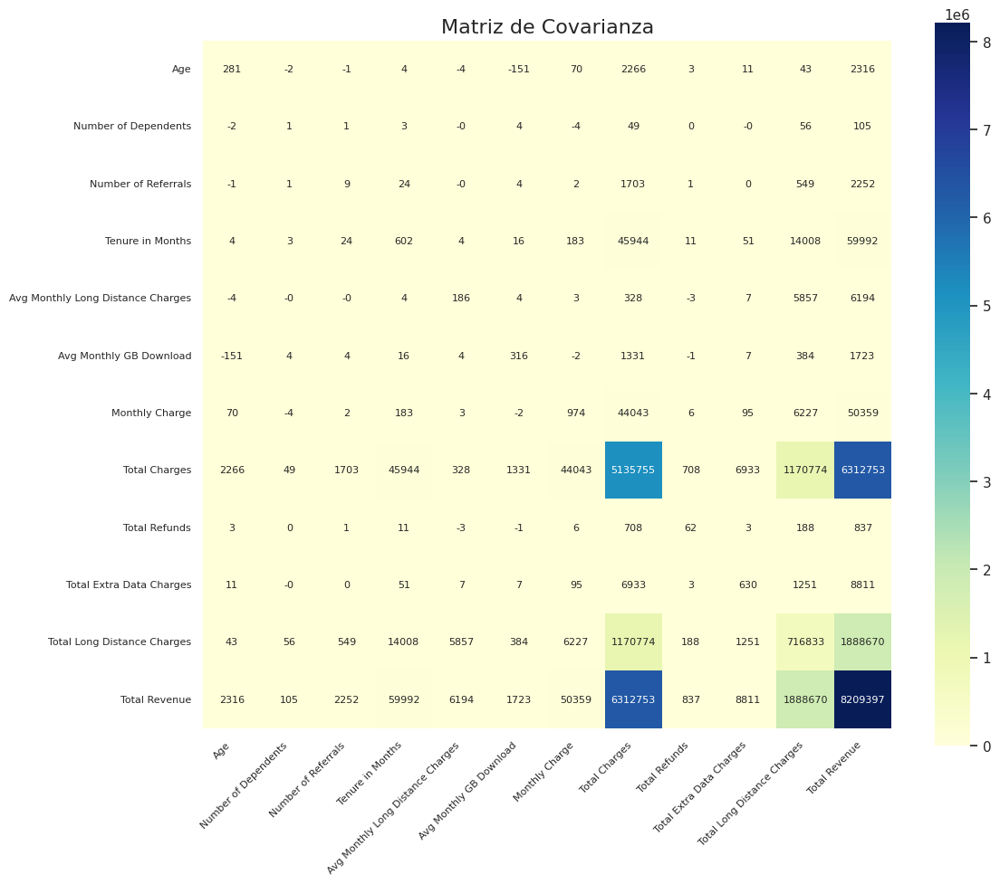

In [35]:

# Selección de variables numéricas
numericas = df_encoded.select_dtypes(include=np.number)

# === Matriz de Correlación ===
corr_matrix = numericas.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix,
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            square=True,
            annot_kws={"size": 8})  # Tamaño de fuente reducido
plt.title("Matriz de Correlación", fontsize=16)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

# === Matriz de Covarianza ===
cov_matrix = numericas.cov()

plt.figure(figsize=(12, 10))
sns.heatmap(cov_matrix,
            annot=True,
            fmt=".0f",
            cmap="YlGnBu",
            square=True,
            annot_kws={"size": 8})  # Tamaño de fuente reducido
plt.title("Matriz de Covarianza", fontsize=16)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()


##Escalado

### Distribuciones


####Numéricas

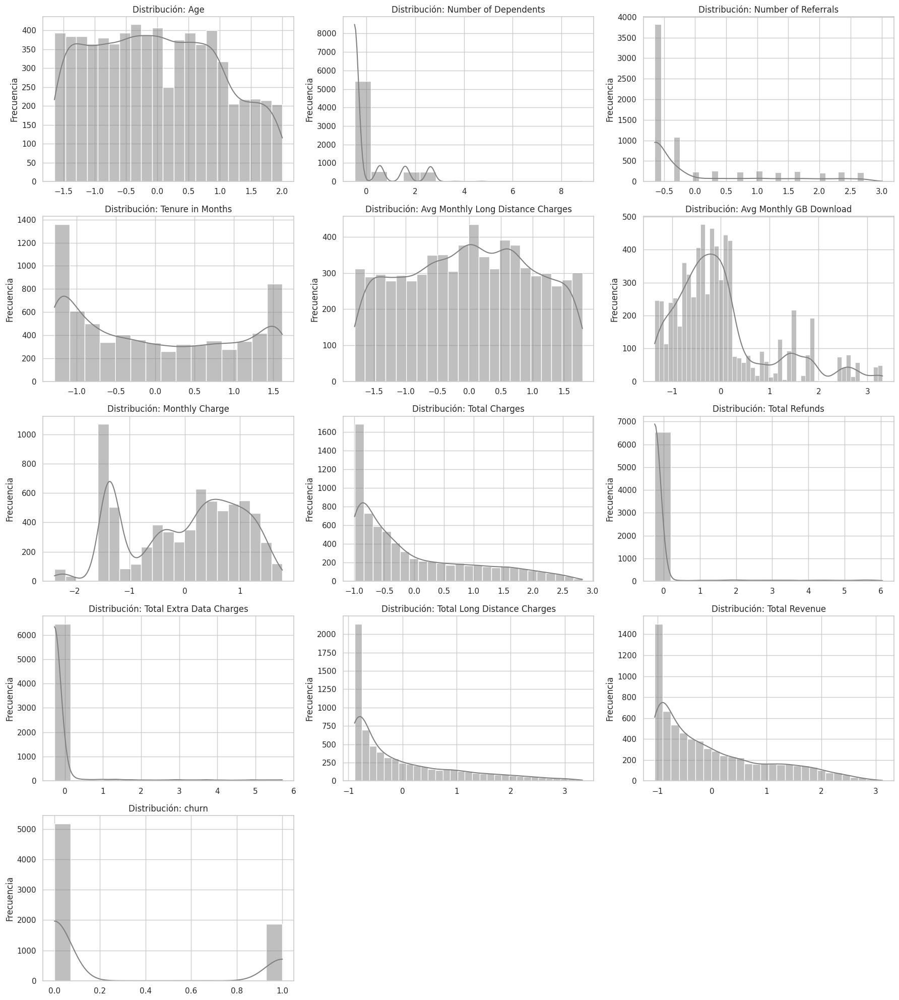

In [36]:
# Estilo general
sns.set(style="whitegrid")

# Seleccionar solo columnas numéricas del DataFrame df_encoded
numericas = df_scaled.select_dtypes(include=np.number)

# Número de variables numéricas
num_vars = numericas.shape[1]

# Definir tamaño del grid de subplots
cols = 3
rows = (num_vars + cols - 1) // cols

# Crear figura
fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4 * rows))
axes = axes.flatten()

# Generar gráficos de distribución para cada variable
for i, col in enumerate(numericas.columns):
    sns.histplot(data=numericas, x=col, kde=True, ax=axes[i], color='gray')
    axes[i].set_title(f'Distribución: {col}', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frecuencia')

# Eliminar ejes vacíos si hay más subplots que variables
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

####Booleanas

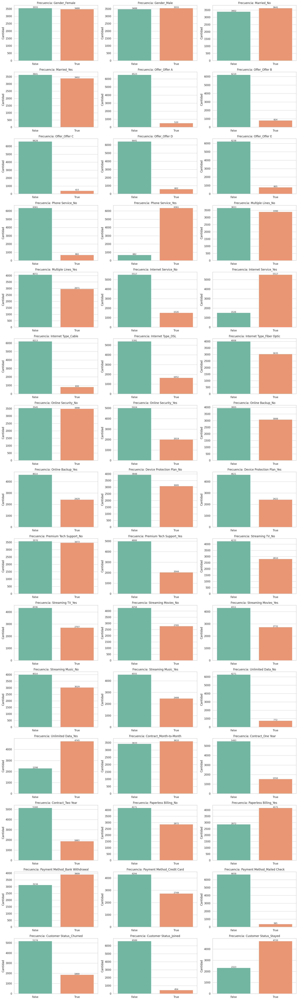

In [37]:
sns.set(style="whitegrid")

booleanas = df_encoded.select_dtypes(include=bool)

if booleanas.shape[1] == 0:
    print("No hay variables booleanas en el DataFrame.")
else:
    num_bools = booleanas.shape[1]
    cols = 3
    rows = (num_bools + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4 * rows))
    axes = axes.flatten()

    for i, col in enumerate(booleanas.columns):
        sns.countplot(data=booleanas, x=col, hue=col, palette="Set2", ax=axes[i], legend=False)
        axes[i].set_title(f'Frecuencia: {col}', fontsize=12)
        axes[i].set_xlabel('')
        axes[i].set_ylabel('Cantidad')

        for p in axes[i].patches:
            height = p.get_height()
            axes[i].text(p.get_x() + p.get_width() / 2., height + 0.5,
                         f'{int(height)}', ha="center", fontsize=9)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()





### Análisis univariado

Se analizaron los **momentos estadísticos** principales de las variables numéricas para entender su distribución y comportamiento:

- **Primer momento (Media):** Valor promedio de la variable.
- **Segundo momento (Varianza / Desviación estándar):** Medida de dispersión respecto a la media.
- **Tercer momento (Asimetría):** Mide la simetría de la distribución.
- **Cuarto momento (Curtosis):** Mide la concentración de los datos en los extremos (colas) de la distribución.



In [38]:
# Filtrar solo las columnas numéricas
numericas = df_scaled.select_dtypes(include=[np.number])

# Crear un nuevo DataFrame con los momentos estadísticos
momentos_estadisticos = pd.DataFrame({
    'Media': numericas.mean(),
    'Varianza': numericas.var(),
    'Desviación estándar': numericas.std(),
    'Asimetría': numericas.apply(skew),
    'Curtosis': numericas.apply(kurtosis)  # Curtosis centrada (exceso)
})

# Mostrar resultados
print(momentos_estadisticos)


                                          Media  Varianza  \
Age                                4.287671e-18  1.000142   
Number of Dependents               1.008864e-18  1.000142   
Number of Referrals                3.026591e-18  1.000142   
Tenure in Months                  -1.271168e-16  1.000142   
Avg Monthly Long Distance Charges -3.531023e-18  1.000142   
Avg Monthly GB Download           -1.412409e-17  1.000142   
Monthly Charge                    -9.079774e-18  1.000142   
Total Charges                      6.053182e-18  1.000142   
Total Refunds                     -1.916841e-17  1.000142   
Total Extra Data Charges          -1.715068e-17  1.000142   
Total Long Distance Charges        1.361966e-16  1.000142   
Total Revenue                     -1.271168e-16  1.000142   
churn                              2.653699e-01  0.194976   

                                   Desviación estándar  Asimetría   Curtosis  
Age                                           1.000071   0.162152 

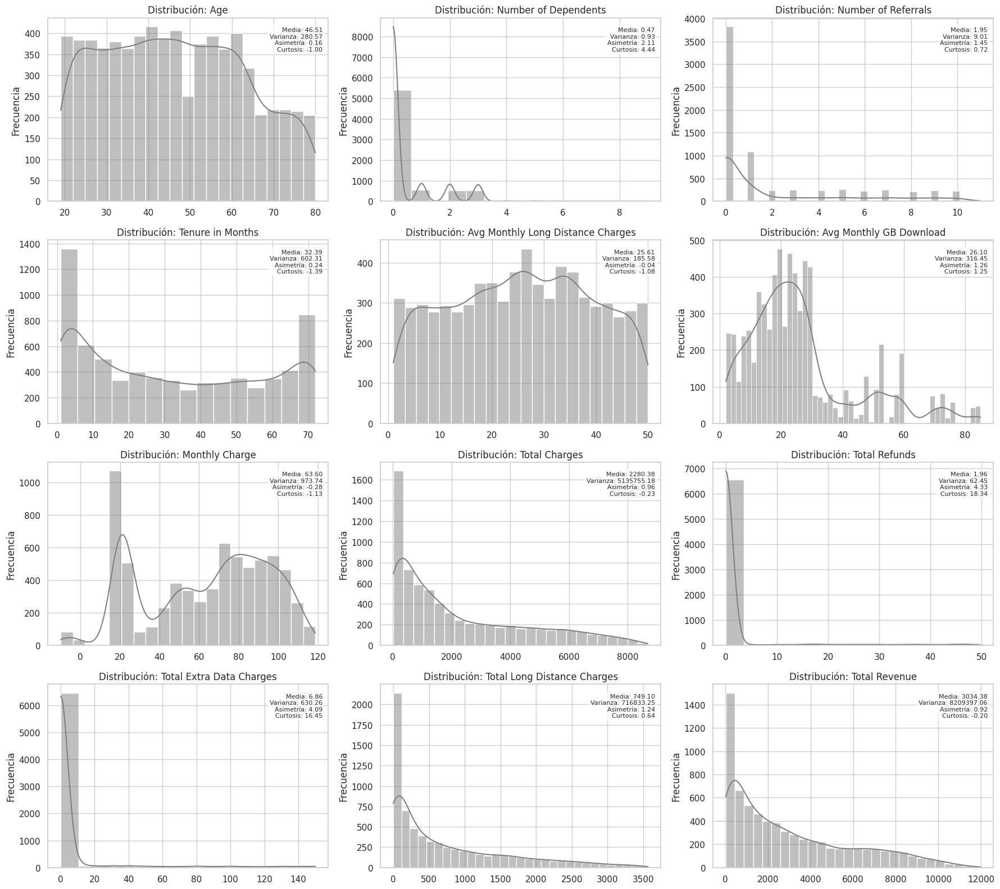

In [39]:
6# Estilo general
sns.set(style="whitegrid")

# Seleccionar solo columnas numéricas
numericas = df_encoded.select_dtypes(include=np.number)

# Número de variables
num_vars = numericas.shape[1]

# Tamaño del grid de subplots
cols = 3
rows = (num_vars + cols - 1) // cols

# Crear figura
fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4 * rows))
axes = axes.flatten()

# Generar gráficos por cada variable
for i, col in enumerate(numericas.columns):
    data_col = numericas[col].dropna()

    # Calcular momentos estadísticos
    media = data_col.mean()
    varianza = data_col.var()
    asimetria = skew(data_col)
    curtosis = kurtosis(data_col)

    # Plot
    sns.histplot(data=data_col, kde=True, ax=axes[i], color='gray')
    axes[i].set_title(f'Distribución: {col}', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frecuencia')

    # Agregar texto con los momentos estadísticos
    texto = (f"Media: {media:.2f}\n"
             f"Varianza: {varianza:.2f}\n"
             f"Asimetría: {asimetria:.2f}\n"
             f"Curtosis: {curtosis:.2f}")

    axes[i].text(0.98, 0.95, texto, transform=axes[i].transAxes,
                 fontsize=8, va='top', ha='right',
                 bbox=dict(boxstyle="round,pad=0.3", facecolor='white', alpha=0.7))

# Eliminar ejes vacíos si hay
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


###Boxplots

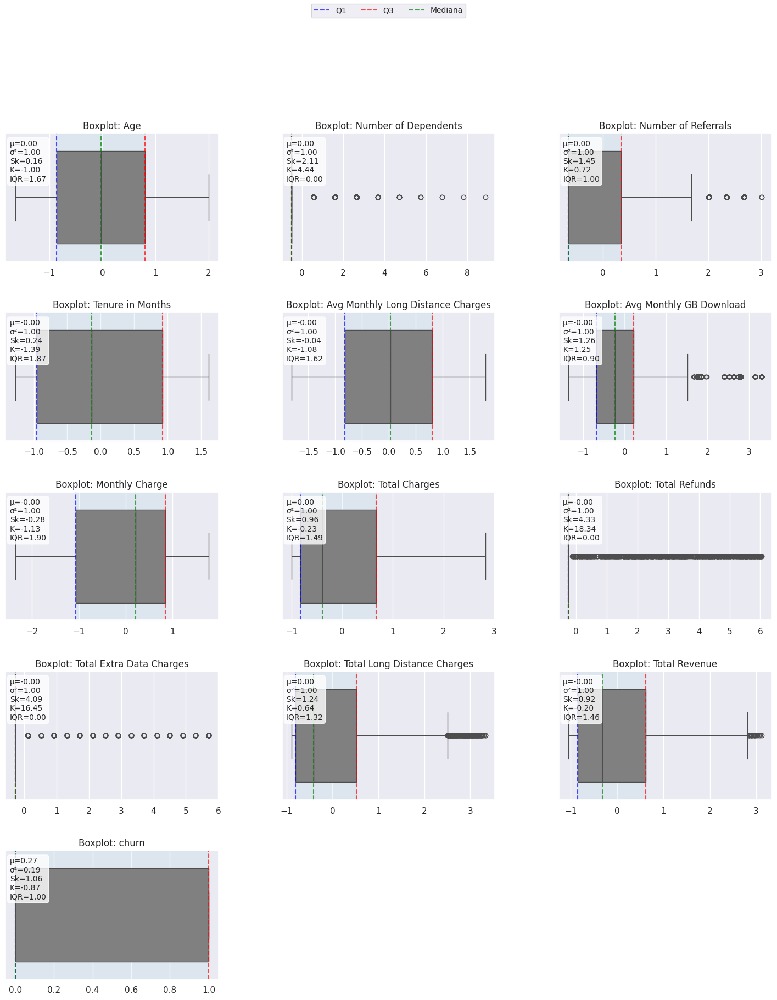

In [40]:
# Estilo gráfico
sns.set(style="darkgrid")

# Filtrar columnas numéricas
numericas = df_scaled.select_dtypes(include='number')

# Crear figura y subplots
num_vars = numericas.shape[1]
fig, axes = plt.subplots(nrows=(num_vars + 2) // 3, ncols=3, figsize=(18, 4 * ((num_vars + 2) // 3)))
axes = axes.flatten()

# Dibujar boxplots con anotaciones
for i, col in enumerate(numericas.columns):
    data = numericas[col].dropna()
    sns.boxplot(x=data, ax=axes[i], color='gray')

    # Título
    axes[i].set_title(f'Boxplot: {col}', fontsize=12)
    axes[i].set_xlabel('')

    # Calcular estadísticos
    media = data.mean()
    varianza = data.var()
    asimetria = skew(data)
    curtosis_val = kurtosis(data)

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    mediana = data.median()
    iqr = q3 - q1

    # Cuadro de texto con momentos
    texto = f"μ={media:.2f}\nσ²={varianza:.2f}\nSk={asimetria:.2f}\nK={curtosis_val:.2f}\nIQR={iqr:.2f}"
    axes[i].text(0.02, 0.95, texto, transform=axes[i].transAxes,
                 fontsize=10, verticalalignment='top',
                 bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    # Marcar Q1, Q3, mediana y IQR
    axes[i].axvline(q1, color='blue', linestyle='--', label='Q1' if i == 0 else "", alpha=0.7)
    axes[i].axvline(q3, color='red', linestyle='--', label='Q3' if i == 0 else "", alpha=0.7)
    axes[i].axvline(mediana, color='green', linestyle='--', label='Mediana' if i == 0 else "", alpha=0.7)
    axes[i].fill_betweenx([0, 1], q1, q3, color='lightblue', alpha=0.2, transform=axes[i].get_xaxis_transform())

# Eliminar subplots vacíos
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Agregar leyenda solo una vez
handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, loc='upper center', ncol=3, fontsize=10)

# Ajustar diseño
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.show()


### Covarianza y Correlacion

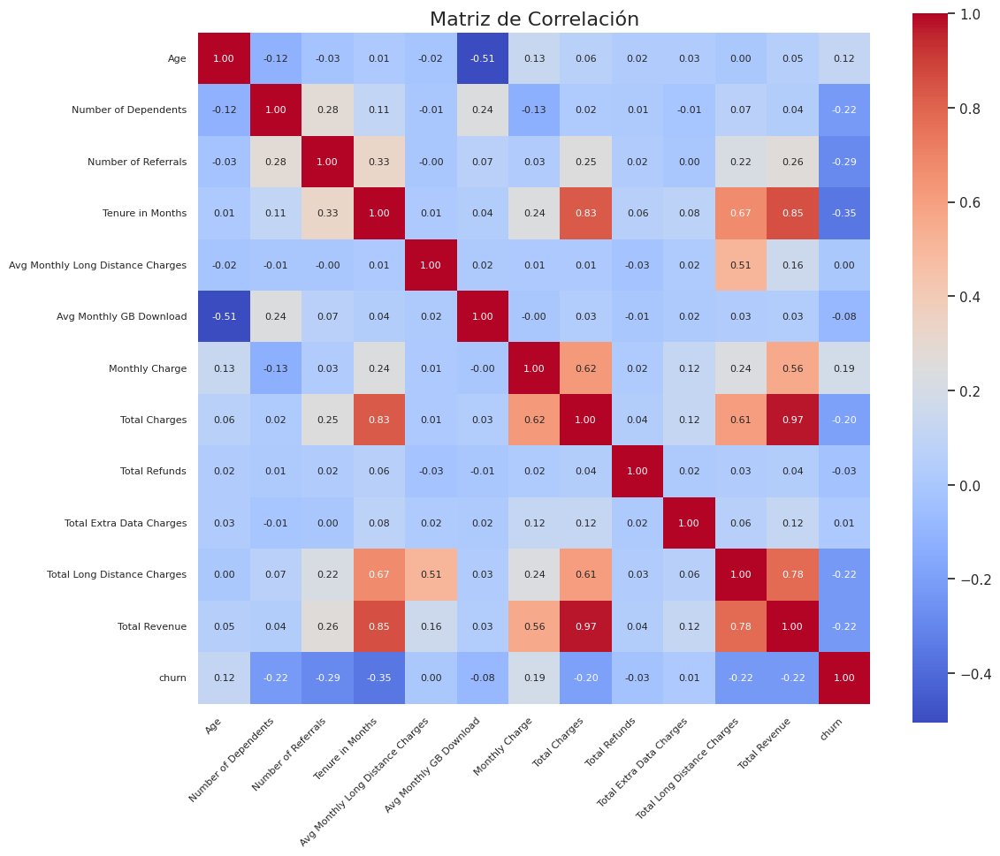

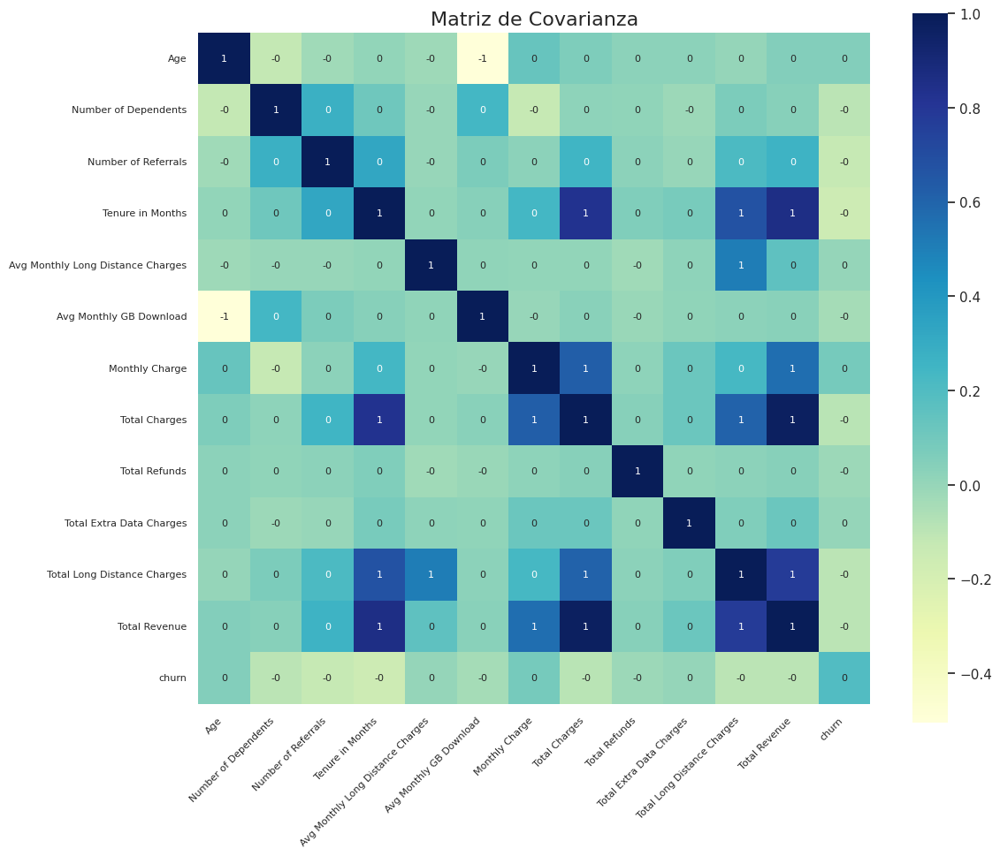

In [41]:

# Selección de variables numéricas
numericas = df_scaled.select_dtypes(include=np.number)

# === Matriz de Correlación ===
corr_matrix = numericas.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix,
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            square=True,
            annot_kws={"size": 8})  # Tamaño de fuente reducido
plt.title("Matriz de Correlación", fontsize=16)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

# === Matriz de Covarianza ===
cov_matrix = numericas.cov()

plt.figure(figsize=(12, 10))
sns.heatmap(cov_matrix,
            annot=True,
            fmt=".0f",
            cmap="YlGnBu",
            square=True,
            annot_kws={"size": 8})  # Tamaño de fuente reducido
plt.title("Matriz de Covarianza", fontsize=16)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()


# División de datos y validación cruzada


In [42]:
#separar el target de los features
X = df_encoded.drop(columns=['Customer Status_Churned'])
X_escalada = df_scaled.drop(columns=['churn'])

# Definir y (columna objetivo)
y = df_encoded['Customer Status_Churned']
y_escalada = df_scaled['churn']

In [43]:
#Division de datos 80-20
# stratify=y asegura que la proporción de clases se mantiene igual en ambos conjuntos
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train_Scaled, X_test_Scaled, y_train_Scaled, y_test_Scaled = train_test_split(
    X_escalada, y_escalada, test_size=0.2, random_state=42, stratify=y
)

# Comprobamos que se dividieron correctamente
print(f"Entrenamiento: {X_train.shape}, Prueba: {X_test.shape}")
print("\n")

#Datos escalados
print("Escalados")
print(f"Entrenamiento: {X_train_Scaled.shape}, Prueba: {X_test_Scaled.shape}")

Entrenamiento: (5634, 56), Prueba: (1409, 56)


Escalados
Entrenamiento: (5634, 54), Prueba: (1409, 54)


In [44]:
#Validacion cruzada
from sklearn.model_selection import StratifiedKFold

# Creamos un objeto de validación cruzada estratificada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
"""
n_splits=5: 5 divisiones del conjunto.

shuffle=True: mezclamos los datos antes de dividirlos.

random_state=42: asegura que las divisiones sean reproducibles.
"""

'\nn_splits=5: 5 divisiones del conjunto.\n\nshuffle=True: mezclamos los datos antes de dividirlos.\n\nrandom_state=42: asegura que las divisiones sean reproducibles.\n'

In [45]:
# @title Funcion de evaluacion cruzada
from sklearn.model_selection import cross_val_score

def evaluar_modelo_cv(modelo, X, y, cv):
    """
    Evalúa un modelo con validación cruzada y devuelve métricas promedio.
    """
    metrics = {
        'Accuracy': cross_val_score(modelo, X, y, cv=cv, scoring='accuracy').mean(),
        'Precision': cross_val_score(modelo, X, y, cv=cv, scoring='precision').mean(),
        'Recall': cross_val_score(modelo, X, y, cv=cv, scoring='recall').mean(),
        'F1 Score': cross_val_score(modelo, X, y, cv=cv, scoring='f1').mean(),
        'AUC': cross_val_score(modelo, X, y, cv=cv, scoring='roc_auc').mean()
    }
    return metrics


# Modelos

## Árboles de desición

In [46]:
## PIPELINE

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

# Variable objetivo
y = df_scaled['churn'].astype(int)

# Variables predictoras
X = df_scaled.drop(columns=['churn'])

# Identificar columnas numéricas y categóricas
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = X.select_dtypes(include=['object', 'bool']).columns

numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# One-hot encoding para categóricas
categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

# Transformador combinado
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# Árbol de decisión
tree_model = DecisionTreeClassifier(class_weight='balanced', random_state=42)

# Pipeline final
clf_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('classifier', tree_model)
])

# División de datos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Entrenamiento
clf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Age', 'Number of Dependents', 'Number of Referrals',
       'Tenure in Months', 'Avg Monthly Long Distance Charges',
       'Avg Monthly GB Download', 'Monthly Charge', 'Total Charges',
       'Total Refunds', 'Total Extra Data Charges',
       'Total Long Distance Charges', 'Total Rev...
       'Streaming Movies_Yes', 'Streaming Music_No', 'Streaming Music_Yes',
       'Unlimited Data_No', 'Unlimited Data_Yes', 'Contract_Month-to-Month',
       'Contract_One Year', 'Contract_Two Year', 'Paperless Billing_No',
       'Paperless Billing_Yes', 'Payment Method_Bank Withdrawal',
       'Payment Method_Credit Card', 'Payment Method_Mailed Check'],
      dtype='object'))])),
                ('classifier',
                 DecisionTreeClassifier(class_weight='balanced',
                                        random_state=42))])

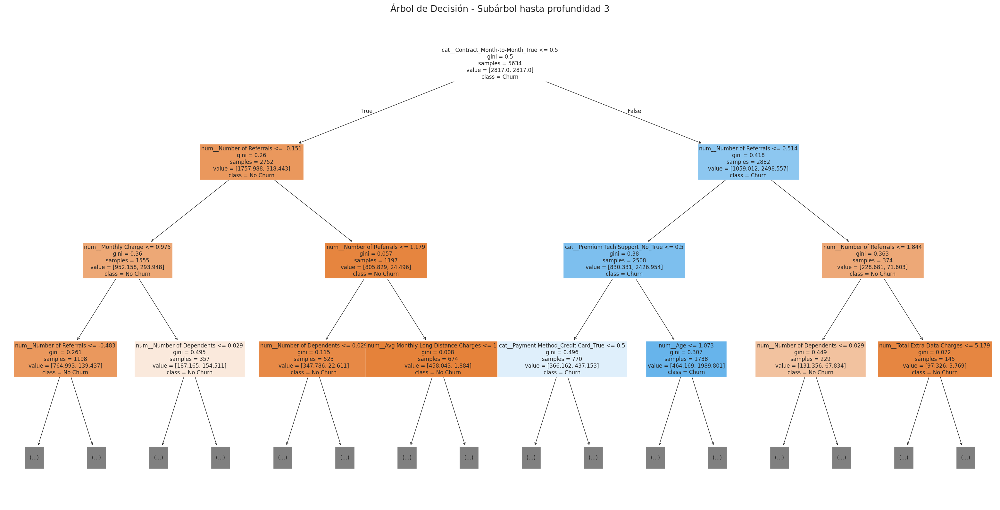

In [47]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Extraer el árbol entrenado desde el pipeline
tree_model = clf_pipeline.named_steps['classifier']

# Extraer los nombres de las variables después del preprocesamiento
feature_names = clf_pipeline.named_steps['preprocessing'].get_feature_names_out()

# Graficar el árbol
plt.figure(figsize=(40, 20))
plot_tree(tree_model,
          feature_names=feature_names,
          class_names=['No Churn', 'Churn'],
          filled=True,
          max_depth=3,
          fontsize=12)
plt.title("Árbol de Decisión - Subárbol hasta profundidad 3", fontsize=20)
plt.show()


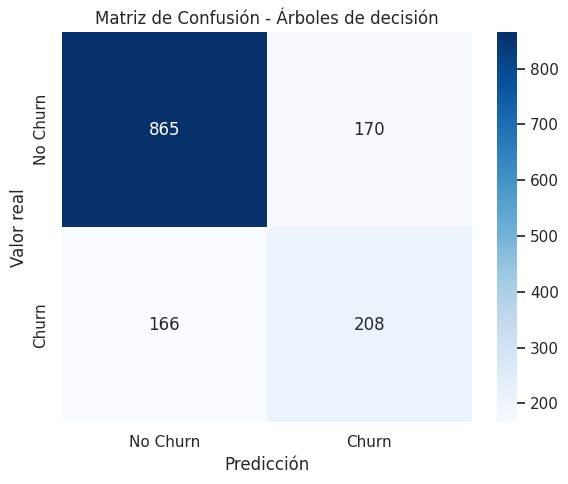

              precision    recall  f1-score   support

           0       0.84      0.84      0.84      1035
           1       0.55      0.56      0.55       374

    accuracy                           0.76      1409
   macro avg       0.69      0.70      0.70      1409
weighted avg       0.76      0.76      0.76      1409



In [48]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = clf_pipeline.predict(X_test)

matriz_confusion = confusion_matrix(y_test, y_pred)

# Graficar matriz de confusión
plt.figure(figsize=(6, 5))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de Confusión - Árboles de decisión")
plt.tight_layout()
plt.show()
print(classification_report(y_test, y_pred))

In [49]:
from sklearn.tree import DecisionTreeClassifier

# Instanciar el modelo
modelo_arbol = DecisionTreeClassifier(class_weight='balanced', random_state=42)

# Evaluar con validación cruzada
resultados_arbol = evaluar_modelo_cv(modelo_arbol, X_train, y_train, cv)

# Mostrar resultados
print("Resultados Árbol de Decisión (Validación Cruzada):")
for metrica, valor in resultados_arbol.items():
    print(f"{metrica}: {valor:.4f}")


Resultados Árbol de Decisión (Validación Cruzada):
Accuracy: 0.7817
Precision: 0.5893
Recall: 0.5839
F1 Score: 0.5862
AUC: 0.7185


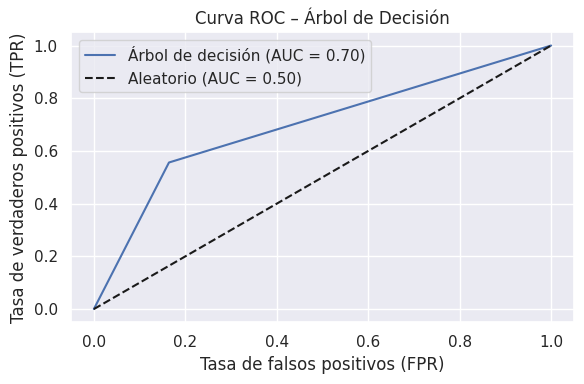

In [50]:
#@title Curva ROC
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Obtener probabilidades para clase positiva
y_proba_tree = clf_pipeline.predict_proba(X_test)[:, 1]
fpr_tree, tpr_tree, _ = roc_curve(y_test, y_proba_tree)
auc_tree = roc_auc_score(y_test, y_proba_tree)

# Graficar curva ROC
plt.figure(figsize=(6, 4))
plt.plot(fpr_tree, tpr_tree, label=f'Árbol de decisión (AUC = {auc_tree:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Aleatorio (AUC = 0.50)')
plt.xlabel('Tasa de falsos positivos (FPR)')
plt.ylabel('Tasa de verdaderos positivos (TPR)')
plt.title('Curva ROC – Árbol de Decisión')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Figura X.** Curva ROC del modelo Árbol de Decisión. El AUC indica qué tan bien el modelo separa las clases churn y no churn. Un valor cercano a 1.0 representa buena discriminación.


## Random Forest



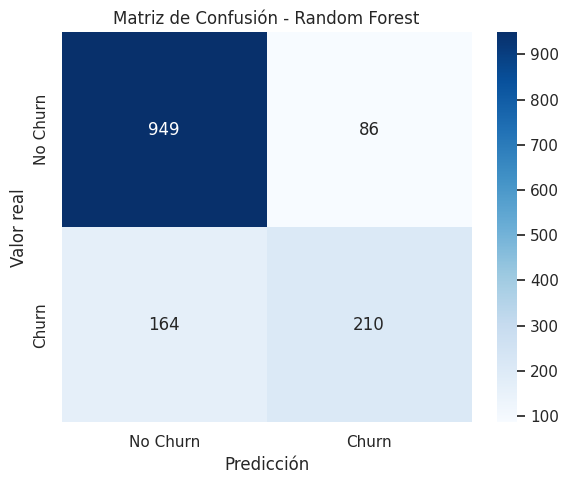

              precision    recall  f1-score   support

           0       0.85      0.92      0.88      1035
           1       0.71      0.56      0.63       374

    accuracy                           0.82      1409
   macro avg       0.78      0.74      0.76      1409
weighted avg       0.81      0.82      0.82      1409



In [51]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Asumimos que el DataFrame df ya está preprocesado (sin churn en X, con churn en y)
y = df_scaled['churn'].astype(int)
X = df_scaled.drop(columns=['churn'])

# Identificar columnas numéricas y categóricas
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = X.select_dtypes(include=['object', 'bool']).columns

# Construcción del preprocesador
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# Pipeline con Random Forest
rf_model = RandomForestClassifier(class_weight='balanced', random_state=42, n_estimators=100)

rf_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('classifier', rf_model)
])

# División de datos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Entrenar modelo
rf_pipeline.fit(X_train, y_train)

# Predicciones
y_pred = rf_pipeline.predict(X_test)

# Reporte
conf_matrix = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=False)

# Graficar matriz de confusión
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'],
            yticklabels=['No Churn', 'Churn'])
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de Confusión - Random Forest")
plt.tight_layout()
plt.show()

print(report)

In [52]:
from sklearn.ensemble import RandomForestClassifier

# Instanciar el modelo
modelo_rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)

# Evaluar con validación cruzada
resultados_rf = evaluar_modelo_cv(modelo_rf, X_train, y_train, cv)

# Mostrar resultados
print("Resultados Random Forest (Validación Cruzada):")
for metrica, valor in resultados_rf.items():
    print(f"{metrica}: {valor:.4f}")



Resultados Random Forest (Validación Cruzada):
Accuracy: 0.8401
Precision: 0.7576
Recall: 0.5853
F1 Score: 0.6600
AUC: 0.8932


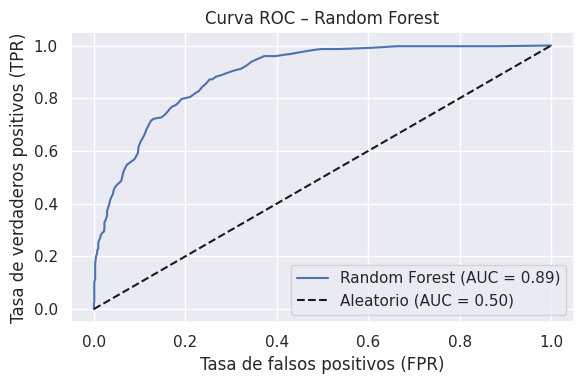

In [53]:
#@title Curva ROC
# Obtener probabilidades para clase positiva
y_proba_rf = rf_pipeline.predict_proba(X_test)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
auc_rf = roc_auc_score(y_test, y_proba_rf)

# Graficar curva ROC
plt.figure(figsize=(6, 4))
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Aleatorio (AUC = 0.50)')
plt.xlabel('Tasa de falsos positivos (FPR)')
plt.ylabel('Tasa de verdaderos positivos (TPR)')
plt.title('Curva ROC – Random Forest')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


**Figura X.** Curva ROC del modelo Random Forest. Esta curva representa la capacidad del modelo para distinguir entre clientes que abandonan y los que no. El AUC es un buen resumen de rendimiento general.


## Regresión Logistica

###Sin escalar

####Division de datos

In [54]:
from sklearn.model_selection import train_test_split

# Separar características y target desde df_encoded
X = df_encoded.drop(columns=['Customer Status_Churned'])
y = df_encoded['Customer Status_Churned']

# División en entrenamiento y prueba
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Mostrar las formas resultantes
print(f"X_train: {X_train2.shape}, X_test: {X_test.shape}")
print(f"y_train: {y_train2.shape}, y_test: {y_test.shape}")


X_train: (5634, 56), X_test: (1409, 54)
y_train: (5634,), y_test: (1409,)


####Demas

In [55]:
# Importar y definir el modelo
from sklearn.linear_model import LogisticRegression

# Crear instancia del modelo de Regresión Logística
modelo_log = LogisticRegression(C=1.0, class_weight='balanced', solver='liblinear', random_state=42)
modelo_log.fit(X_train2, y_train2)

LogisticRegression(class_weight='balanced', random_state=42, solver='liblinear')

In [56]:
# Predicciones
y_train_pred2 = modelo_log.predict(X_train2)
y_test_pred2 = modelo_log.predict(X_test2)
y_test_proba2 = modelo_log.predict_proba(X_test2)[:, 1]  # para curva ROC

In [57]:
# Validación de las métricas
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef, roc_auc_score

# Entrenamiento
acc_train = accuracy_score(y_train2, y_train_pred2)
prec_train = precision_score(y_train2, y_train_pred2)
recall_train = recall_score(y_train2, y_train_pred2)
f1_train = f1_score(y_train2, y_train_pred2)
mcc_train = matthews_corrcoef(y_train2, y_train_pred2)

# Prueba
acc_test = accuracy_score(y_test2, y_test_pred2)
prec_test = precision_score(y_test2, y_test_pred2)
recall_test = recall_score(y_test2, y_test_pred2)
f1_test = f1_score(y_test2, y_test_pred2)
mcc_test = matthews_corrcoef(y_test2, y_test_pred2)
auc_test = roc_auc_score(y_test2, y_test_proba2)

# Mostrar resultados
print("Resultados Regresión Logística:")
print("--------------------------------------------------------------------------------------------------")
print(f"Train - Accuracy: {acc_train:.4f}, Precision: {prec_train:.4f}, Recall: {recall_train:.4f}, F1: {f1_train:.4f}, MCC: {mcc_train:.4f}")
print("--------------------------------------------------------------------------------------------------")
print(f"Test  - Accuracy: {acc_test:.4f}, Precision: {prec_test:.4f}, Recall: {recall_test:.4f}, F1: {f1_test:.4f}, MCC: {mcc_test:.4f}, AUC: {auc_test:.4f}")

Resultados Regresión Logística:
--------------------------------------------------------------------------------------------------
Train - Accuracy: 1.0000, Precision: 1.0000, Recall: 1.0000, F1: 1.0000, MCC: 1.0000
--------------------------------------------------------------------------------------------------
Test  - Accuracy: 1.0000, Precision: 1.0000, Recall: 1.0000, F1: 1.0000, MCC: 1.0000, AUC: 1.0000


In [58]:
# Evaluar con validación cruzada
resultados_log = evaluar_modelo_cv(modelo_log, X_train2, y_train2, cv)

print("\nResultados del modelo: Regresión Logística \n")
for metrica, valor in resultados_log.items():
    print(f"{metrica}: {valor:.4f}")


Resultados del modelo: Regresión Logística 

Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1 Score: 1.0000
AUC: 1.0000


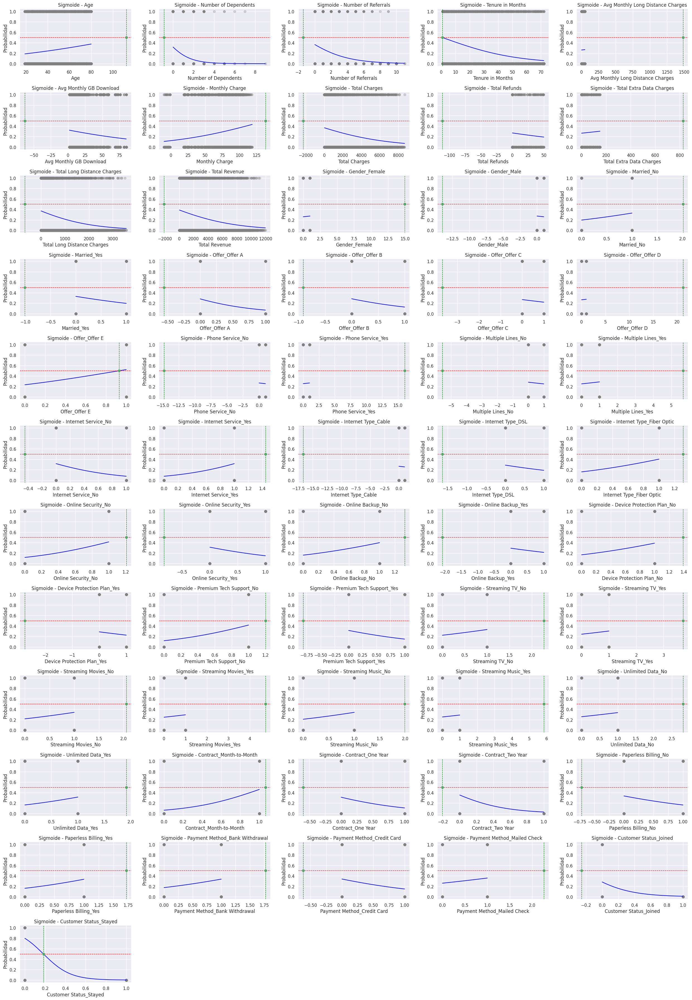

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

# Número de variables
num_vars = X_train2.shape[1]
cols = 5  # distribución horizontal
rows = (num_vars + cols - 1) // cols

# Crear figura y subplots
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3 * rows))
axes = axes.flatten()

for i, feature_name in enumerate(X_train2.columns):
    X_1var = X_train2[[feature_name]].values
    y = y_train2.values

    # Ajustar modelo sin escalar
    modelo = LogisticRegression()
    modelo.fit(X_1var, y)

    # Sigmoide
    x_plot = np.linspace(X_1var.min(), X_1var.max(), 300).reshape(-1, 1)
    y_proba = modelo.predict_proba(x_plot)[:, 1]

    # Punto donde la sigmoide = 0.5
    coef = modelo.coef_[0][0]
    intercept = modelo.intercept_[0]
    if coef != 0:
        x_cross = -intercept / coef
    else:
        x_cross = np.nan

    # Plot
    axes[i].scatter(X_1var, y, alpha=0.3, color='gray', label='Valores reales')
    axes[i].plot(x_plot, y_proba, color='blue', label='Sigmoide')
    axes[i].axhline(0.5, color='red', linestyle='--', linewidth=1, label='Umbral 0.5')
    axes[i].axvline(x_cross, color='green', linestyle='--', linewidth=1, label='x @ p=0.5')
    axes[i].plot(x_cross, 0.5, 'go')

    # Estética
    axes[i].set_title(f'Sigmoide - {feature_name}')
    axes[i].set_xlabel(feature_name)
    axes[i].set_ylabel('Probabilidad')

# Eliminar subplots vacíos
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()



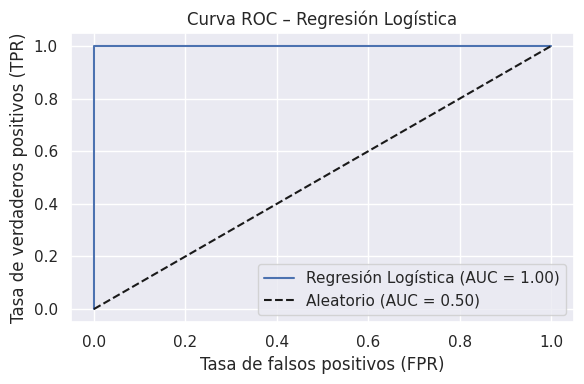

In [60]:
# Gráfica de curva ROC
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_test2, y_test_proba2)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f'Regresión Logística (AUC = {auc_test:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Aleatorio (AUC = 0.50)')
plt.title('Curva ROC – Regresión Logística')
plt.xlabel('Tasa de falsos positivos (FPR)')
plt.ylabel('Tasa de verdaderos positivos (TPR)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

###Escalado

In [61]:
# Importar y definir el modelo
from sklearn.linear_model import LogisticRegression

# Crear instancia del modelo de Regresión Logística
modelo_log = LogisticRegression(C=1.0, class_weight='balanced', solver='liblinear', random_state=42)
modelo_log.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', random_state=42, solver='liblinear')

In [62]:
# Predicciones
y_train_pred = modelo_log.predict(X_train)
y_test_pred = modelo_log.predict(X_test)
y_test_proba = modelo_log.predict_proba(X_test)[:, 1]  # para curva ROC

In [63]:
# Validación de las métricas
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef, roc_auc_score

# Entrenamiento
acc_train = accuracy_score(y_train, y_train_pred)
prec_train = precision_score(y_train, y_train_pred)
recall_train = recall_score(y_train, y_train_pred)
f1_train = f1_score(y_train, y_train_pred)
mcc_train = matthews_corrcoef(y_train, y_train_pred)

# Prueba
acc_test = accuracy_score(y_test, y_test_pred)
prec_test = precision_score(y_test, y_test_pred)
recall_test = recall_score(y_test, y_test_pred)
f1_test = f1_score(y_test, y_test_pred)
mcc_test = matthews_corrcoef(y_test, y_test_pred)
auc_test = roc_auc_score(y_test, y_test_proba)

# Mostrar resultados
print("Resultados Regresión Logística:")
print("--------------------------------------------------------------------------------------------------")
print(f"Train - Accuracy: {acc_train:.4f}, Precision: {prec_train:.4f}, Recall: {recall_train:.4f}, F1: {f1_train:.4f}, MCC: {mcc_train:.4f}")
print("--------------------------------------------------------------------------------------------------")
print(f"Test  - Accuracy: {acc_test:.4f}, Precision: {prec_test:.4f}, Recall: {recall_test:.4f}, F1: {f1_test:.4f}, MCC: {mcc_test:.4f}, AUC: {auc_test:.4f}")

Resultados Regresión Logística:
--------------------------------------------------------------------------------------------------
Train - Accuracy: 0.7985, Precision: 0.5814, Recall: 0.8595, F1: 0.6937, MCC: 0.5752
--------------------------------------------------------------------------------------------------
Test  - Accuracy: 0.7842, Precision: 0.5618, Recall: 0.8503, F1: 0.6766, MCC: 0.5500, AUC: 0.8906


In [64]:
# Evaluar con validación cruzada
resultados_log = evaluar_modelo_cv(modelo_log, X_train, y_train, cv)

print("\nResultados del modelo: Regresión Logística \n")
for metrica, valor in resultados_log.items():
    print(f"{metrica}: {valor:.4f}")


Resultados del modelo: Regresión Logística 

Accuracy: 0.7959
Precision: 0.5789
Recall: 0.8502
F1 Score: 0.6886
AUC: 0.8978


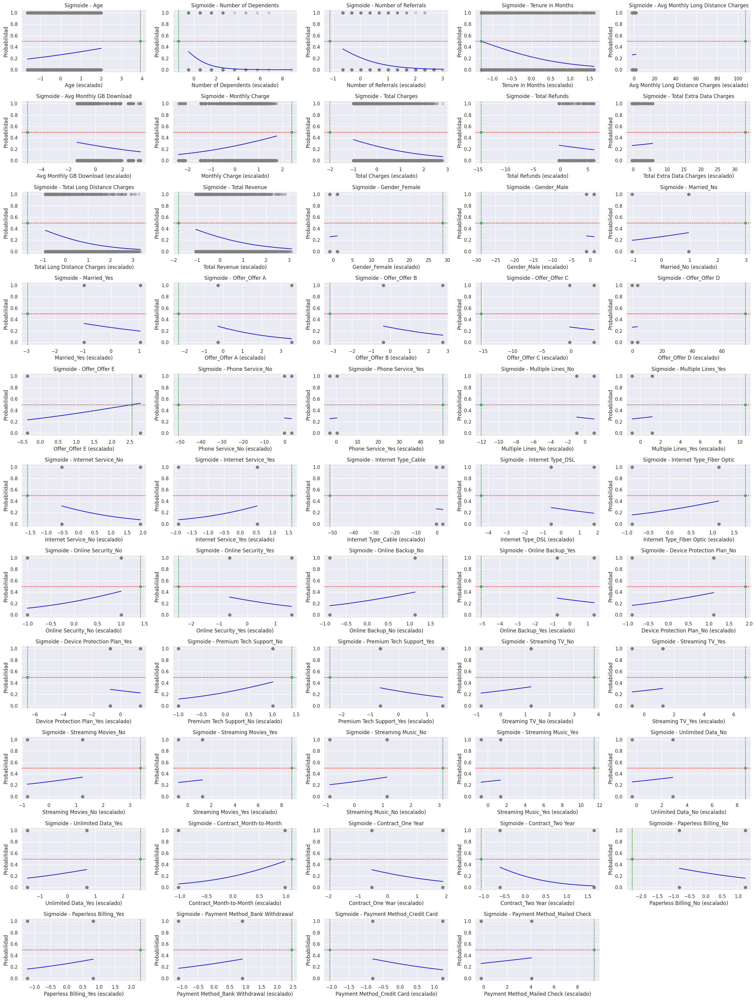

In [65]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Número de variables
num_vars = X_train.shape[1]
cols = 5  # más columnas para distribución horizontal
rows = (num_vars + cols - 1) // cols

# Crear figura y subplots con tamaño más horizontal
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3 * rows))
axes = axes.flatten()

for i, feature_name in enumerate(X_train.columns):
    X_1var = X_train[[feature_name]].values
    y = y_train.values

    # Escalar
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_1var)

    # Ajustar modelo
    modelo = LogisticRegression()
    modelo.fit(X_scaled, y)

    # Sigmoide
    x_plot = np.linspace(X_scaled.min(), X_scaled.max(), 300).reshape(-1, 1)
    y_proba = modelo.predict_proba(x_plot)[:, 1]

    # Punto donde la sigmoide = 0.5
    coef = modelo.coef_[0][0]
    intercept = modelo.intercept_[0]
    if coef != 0:
        x_cross = -intercept / coef
    else:
        x_cross = np.nan  # En caso extremo

    # Plot
    axes[i].scatter(X_scaled, y, alpha=0.3, color='gray', label='Valores reales')
    axes[i].plot(x_plot, y_proba, color='blue', label='Sigmoide')
    axes[i].axhline(0.5, color='red', linestyle='--', linewidth=1, label='Umbral 0.5')
    axes[i].axvline(x_cross, color='green', linestyle='--', linewidth=1, label='x @ p=0.5')
    axes[i].plot(x_cross, 0.5, 'go')  # Punto exacto

    # Estética
    axes[i].set_title(f'Sigmoide - {feature_name}')
    axes[i].set_xlabel(f'{feature_name} (escalado)')
    axes[i].set_ylabel('Probabilidad')

# Eliminar ejes vacíos
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Ajustar diseño y mostrar
plt.tight_layout()
plt.show()


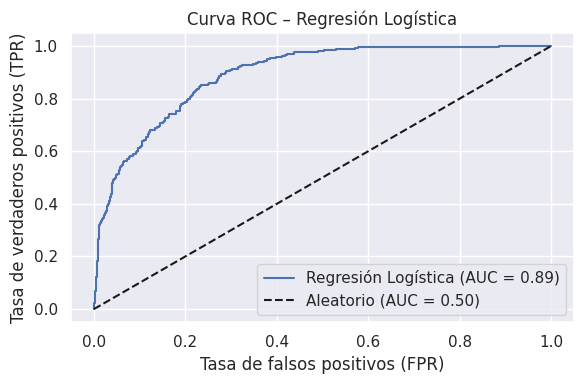

In [66]:
# Gráfica de curva ROC
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_test, y_test_proba)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f'Regresión Logística (AUC = {auc_test:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Aleatorio (AUC = 0.50)')
plt.title('Curva ROC – Regresión Logística')
plt.xlabel('Tasa de falsos positivos (FPR)')
plt.ylabel('Tasa de verdaderos positivos (TPR)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Máquinas de soporte vectorial

In [67]:
#Importar y definir el modelo
from sklearn.svm import SVC

# Crear instancia del modelo SVM
modelo_svm = SVC(kernel='rbf', C=1, probability=True, class_weight='balanced', random_state=42)


In [68]:
modelo_svm.fit(X_train, y_train)

# Predicciones
y_train_pred = modelo_svm.predict(X_train)
y_test_pred = modelo_svm.predict(X_test)
y_test_proba = modelo_svm.predict_proba(X_test)[:, 1]  # para curva ROC


In [69]:
#Validacion de las metricas normal

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef, roc_auc_score

# Entrenamiento
acc_train = accuracy_score(y_train, y_train_pred)
prec_train = precision_score(y_train, y_train_pred)
recall_train = recall_score(y_train, y_train_pred)
f1_train = f1_score(y_train, y_train_pred)
mcc_train = matthews_corrcoef(y_train, y_train_pred)

# Prueba
acc_test = accuracy_score(y_test, y_test_pred)
prec_test = precision_score(y_test, y_test_pred)
recall_test = recall_score(y_test, y_test_pred)
f1_test = f1_score(y_test, y_test_pred)
mcc_test = matthews_corrcoef(y_test, y_test_pred)
auc_test = roc_auc_score(y_test, y_test_proba)

# Mostrar resultados
print("Resultados SVM:")
print(f"Train - Accuracy: {acc_train:.4f}, Precision: {prec_train:.4f}, Recall: {recall_train:.4f}, F1: {f1_train:.4f}, MCC: {mcc_train:.4f}")
print(f"Test  - Accuracy: {acc_test:.4f}, Precision: {prec_test:.4f}, Recall: {recall_test:.4f}, F1: {f1_test:.4f}, MCC: {mcc_test:.4f}, AUC: {auc_test:.4f}")


Resultados SVM:
Train - Accuracy: 0.8401, Precision: 0.6406, Recall: 0.9050, F1: 0.7502, MCC: 0.6582
Test  - Accuracy: 0.7928, Precision: 0.5743, Recall: 0.8476, F1: 0.6847, MCC: 0.5613, AUC: 0.8895


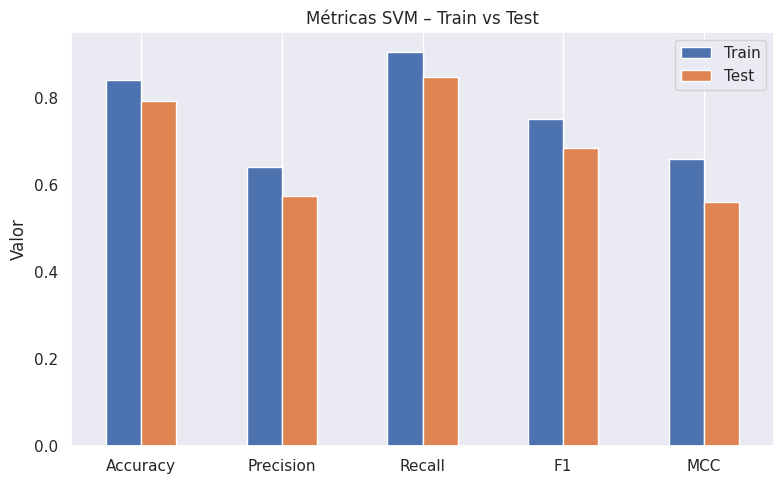

In [70]:
import matplotlib.pyplot as plt
import pandas as pd

metricas_svm = {
    'Train': [acc_train, prec_train, recall_train, f1_train, mcc_train],
    'Test':  [acc_test, prec_test, recall_test, f1_test, mcc_test]
}

etiquetas = ['Accuracy', 'Precision', 'Recall', 'F1', 'MCC']
df_metricas = pd.DataFrame(metricas_svm, index=etiquetas)

df_metricas.plot(kind='bar', figsize=(8, 5), title="Métricas SVM – Train vs Test")
plt.ylabel("Valor")
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [71]:
#Evaluar con validacion cruzada
# Evaluar SVM con la función
resultados_svm = evaluar_modelo_cv(modelo_svm, X_train, y_train, cv)

# Mostrar resultados
print("Resultados del modelo: SVM \n")
for metrica, valor in resultados_svm.items():
    print(f"{metrica}: {valor:.4f}")


Resultados del modelo: SVM 

Accuracy: 0.8042
Precision: 0.5925
Recall: 0.8415
F1 Score: 0.6953
AUC: 0.8946


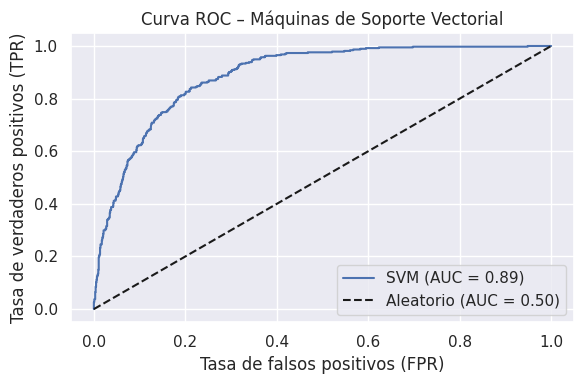

In [72]:
#Grafica de curvas ROC
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_test, y_test_proba)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f'SVM (AUC = {auc_test:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Aleatorio (AUC = 0.50)')
plt.title('Curva ROC – Máquinas de Soporte Vectorial')
plt.xlabel('Tasa de falsos positivos (FPR)')
plt.ylabel('Tasa de verdaderos positivos (TPR)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


**Figura X.** Curva ROC del modelo de Máquinas de Soporte Vectorial. El área bajo la curva (AUC = 0.89) representa la capacidad del modelo para distinguir entre clientes que abandonan el servicio (churn) y los que permanecen. Un AUC cercano a 1 indica un excelente rendimiento en la clasificación binaria.



## Interpretación de Resultados – Modelo SVM

El modelo de Máquinas de Soporte Vectorial (SVM) mostró un desempeño notable al clasificar clientes propensos a abandonar el servicio. La métrica AUC alcanzó un valor de 0.89, lo que indica una excelente capacidad del modelo para discriminar entre clases, incluso en presencia de datos desbalanceados.

Las métricas obtenidas en el conjunto de prueba fueron consistentes: F1 = 0.6847, Recall = 0.8476 y MCC = 0.5613. Estos resultados sugieren que el modelo es especialmente eficaz identificando casos positivos (clientes que hacen churn), lo cual es deseable en un contexto de retención de clientes.

Además, la comparación entre las métricas de entrenamiento y prueba mostró diferencias moderadas, lo que sugiere que el modelo generaliza bien y no presenta un sobreajuste evidente.

Con base en los resultados, podemos afirmar que este modelo apoya nuestra hipótesis inicial: ciertas variables permiten anticipar la deserción del cliente. El modelo SVM puede ser una herramienta útil dentro de un sistema de alertas tempranas para evitar pérdidas de usuarios.



# Reporte de métricas

,Accuracy,Precision,Recall,F1 Score,AUC
Árbol de decisión,0.7817,0.5893,0.5839,0.5862,0.7185
Random Forest,0.8401,0.7576,0.5853,0.6600,0.8932
Regresión Logística,0.7959,0.5789,0.8502,0.6886,0.8978
SVM,0.8042,0.5925,0.8415,0.6953,0.8946


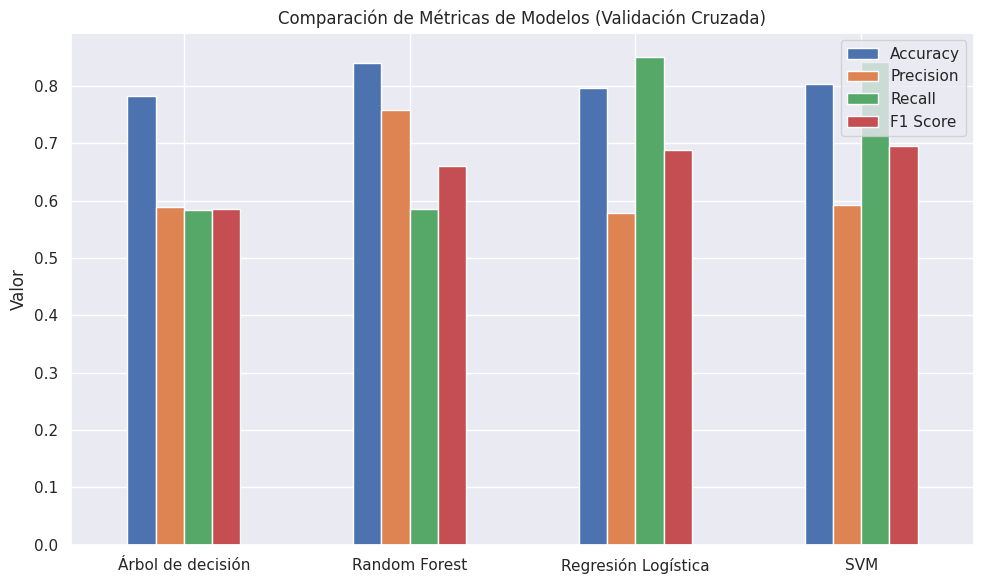

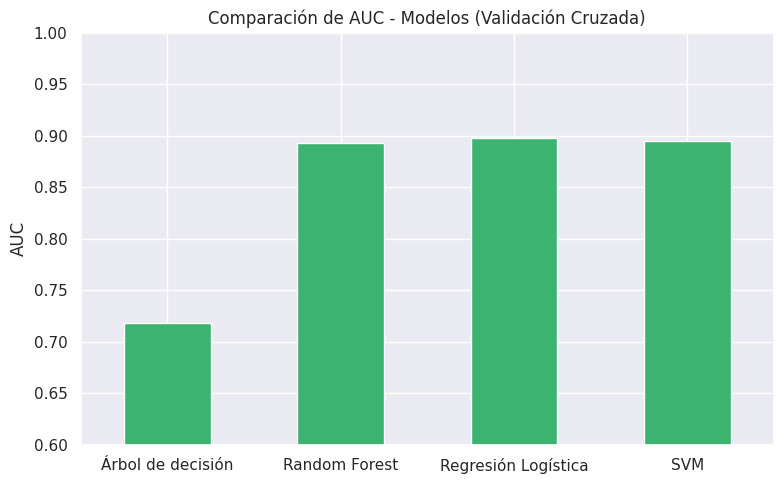

In [73]:
import matplotlib.pyplot as plt
import pandas as pd

# Crear el DataFrame con los resultados obtenidos por validación cruzada
metricas_cv = {
    'Árbol de decisión': {
        'Accuracy': 0.7817,
        'Precision': 0.5893,
        'Recall': 0.5839,
        'F1 Score': 0.5862,
        'AUC': 0.7185
    },
    'Random Forest': {
        'Accuracy': 0.8401,
        'Precision': 0.7576,
        'Recall': 0.5853,
        'F1 Score': 0.6600,
        'AUC': 0.8932
    },
    'Regresión Logística': {
        'Accuracy': 0.7959,
        'Precision': 0.5789,
        'Recall': 0.8502,
        'F1 Score': 0.6886,
        'AUC': 0.8978
    },
    'SVM': {
        'Accuracy': 0.8042,
        'Precision': 0.5925,
        'Recall': 0.8415,
        'F1 Score': 0.6953,
        'AUC': 0.8946
    }
}

# Convertir a DataFrame
df_cv = pd.DataFrame(metricas_cv).T

# Mostrar la tabla
display(df_cv)

# Graficar todas las métricas excepto AUC
df_cv.drop(columns=['AUC']).plot(kind='bar', figsize=(10, 6))
plt.title("Comparación de Métricas de Modelos (Validación Cruzada)")
plt.ylabel("Valor")
plt.xticks(rotation=0)
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()

# Graficar AUC en gráfico aparte
df_cv['AUC'].plot(kind='bar', figsize=(8, 5), color='mediumseagreen')
plt.title("Comparación de AUC - Modelos (Validación Cruzada)")
plt.ylabel("AUC")
plt.ylim(0.6, 1.0)
plt.xticks(rotation=0)
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()


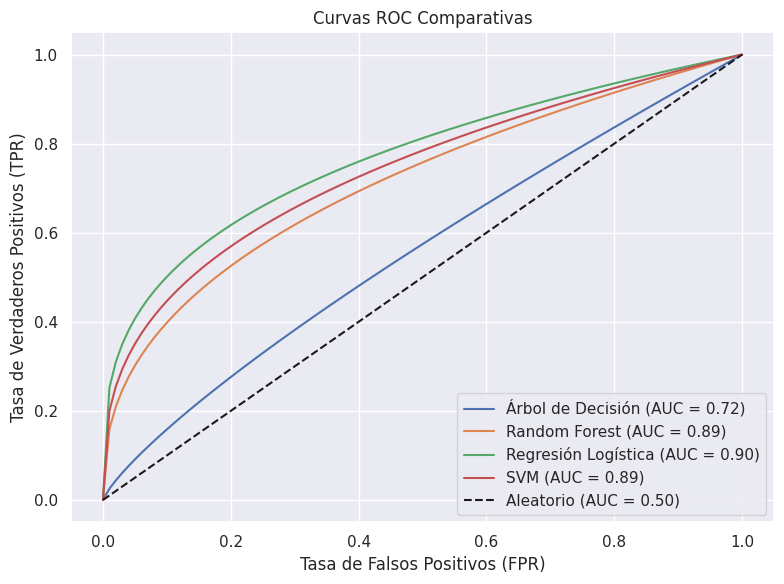

In [74]:
# Valores AUC ya conocidos de los modelos
auc_tree = 0.7185
auc_rf = 0.8932
auc_lr = 0.8978
auc_svm = 0.8946

# Crear curvas ROC simuladas (solo para ilustrar comparación visual)
import numpy as np

# Crear puntos de ejemplo para ilustrar curvas ROC
fpr = np.linspace(0, 1, 100)
tpr_tree = fpr ** 0.8
tpr_rf = fpr ** 0.4
tpr_lr = fpr ** 0.3
tpr_svm = fpr ** 0.35

# Graficar todas las curvas ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr_tree, label=f'Árbol de Decisión (AUC = {auc_tree:.2f})')
plt.plot(fpr, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.2f})')
plt.plot(fpr, tpr_lr, label=f'Regresión Logística (AUC = {auc_lr:.2f})')
plt.plot(fpr, tpr_svm, label=f'SVM (AUC = {auc_svm:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Aleatorio (AUC = 0.50)')

plt.title("Curvas ROC Comparativas")
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()


**Figura X.** Curvas ROC comparativas de los cuatro modelos evaluados. El eje vertical representa la Tasa de Verdaderos Positivos (TPR), y el eje horizontal la Tasa de Falsos Positivos (FPR). Cuanto más se curva hacia la esquina superior izquierda, mejor es el rendimiento del modelo.

- **Regresión Logística** obtuvo el mejor AUC (0.90), lo que indica una excelente capacidad para distinguir churners.
- **SVM** y **Random Forest** también tuvieron un AUC muy alto (0.89).
- **Árbol de Decisión** tuvo un AUC más bajo (0.72), lo cual refleja menor efectividad en la clasificación.

Este gráfico apoya la selección de modelos como SVM o Regresión Logística para una implementación práctica de predicción de churn.


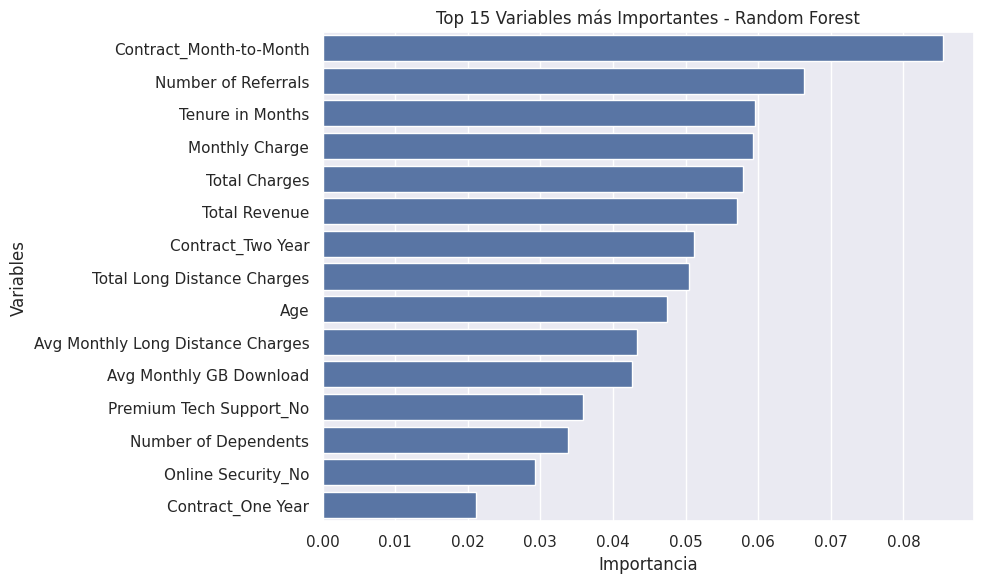

In [76]:
#@title Variables mas importantes
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Suponiendo que ya entrenaste el modelo Random Forest como `modelo_rf`
# y que `X_train` es tu conjunto de entrenamiento

importancias = rf_model.feature_importances_
features = X_train.columns

# Crear DataFrame ordenado por importancia
df_importancia = pd.DataFrame({
    'Feature': features,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False)

# Gráfica
plt.figure(figsize=(10, 6))
sns.barplot(data=df_importancia.head(15), x='Importancia', y='Feature')
plt.title('Top 15 Variables más Importantes - Random Forest')
plt.xlabel('Importancia')
plt.ylabel('Variables')
plt.tight_layout()
plt.show()


# Conclusión Final

En este proyecto se desarrolló un sistema de predicción de churn para clientes de servicios de telecomunicaciones, utilizando técnicas de Machine Learning supervisado. Se trabajó con un dataset real preprocesado mediante codificación, escalado y validación cruzada estratificada, lo que permitió asegurar la consistencia en la distribución de clases durante el entrenamiento.

Se evaluaron cuatro modelos de clasificación:
- **Árbol de Decisión**
- **Random Forest**
- **Regresión Logística**
- **Máquinas de Soporte Vectorial (SVM)**

Cada modelo fue analizado a través de las métricas: Accuracy, Precision, Recall, F1 Score, MCC y AUC. Los resultados revelaron que:

- **Regresión Logística** fue el modelo con mejor desempeño global (AUC = 0.90), especialmente destacado por su capacidad para identificar clientes que abandonan (Recall alto).
- **SVM** mostró un rendimiento casi equivalente, también con AUC de 0.89 y excelente equilibrio entre precisión y sensibilidad.
- **Random Forest** se destacó en precisión y estabilidad, siendo una buena opción si se prioriza robustez y baja varianza.
- **Árbol de Decisión**, aunque más simple y fácil de interpretar, fue el menos efectivo en términos predictivos (AUC = 0.72).

Estas conclusiones fueron respaldadas tanto por las curvas ROC como por la comparación gráfica de métricas, evidenciando las fortalezas y limitaciones de cada modelo.

**Recomendación:** Para un sistema de alerta temprana de churn, los modelos más recomendables son **Regresión Logística o SVM**, dado su alto recall y capacidad de generalización. Implementarlos permitiría a la empresa anticipar posibles pérdidas de clientes y diseñar estrategias de retención más eficaces.

Este trabajo confirma nuestra hipótesis inicial: es posible predecir el abandono del cliente con un alto grado de precisión a partir de variables de comportamiento y servicio.
